# Netflix Customer Churn: Drivers and Prediction

School project. Dataset: Netflix Customer Churn (Kaggle, 5,000 customers, synthetic). The notebook tests which variables are linked to churn, compares classification models, and estimates customer lifetime value and retention campaign ROI from stated assumptions.

Run from the `notebooks/` folder so the relative data path works.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report, roc_auc_score
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc
from scipy.stats import pearsonr, chi2_contingency, ttest_ind
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load Dataset
df = pd.read_csv('../data/netflix_customer_churn.csv')
print("Dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Dataset shape: (5000, 14)

Missing values: 0
Duplicates: 0


In [3]:
# Transformations for skewed variables 
for col in ['watch_hours', 'avg_watch_time_per_day', 'monthly_fee', 'last_login_days']:
    if col in df.columns:
        df[f'{col}_log'] = np.log1p(df[col].clip(lower=0))
        df[f'{col}_sqrt'] = np.sqrt(df[col].clip(lower=0))
print("Added log and sqrt variants for key skewed variables.")


Added log and sqrt variants for key skewed variables.


In [4]:
# replace NA basic for numeric
num_cols = df.select_dtypes(include="number").columns
if len(num_cols) > 0:
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())



Churn rate: 0.503


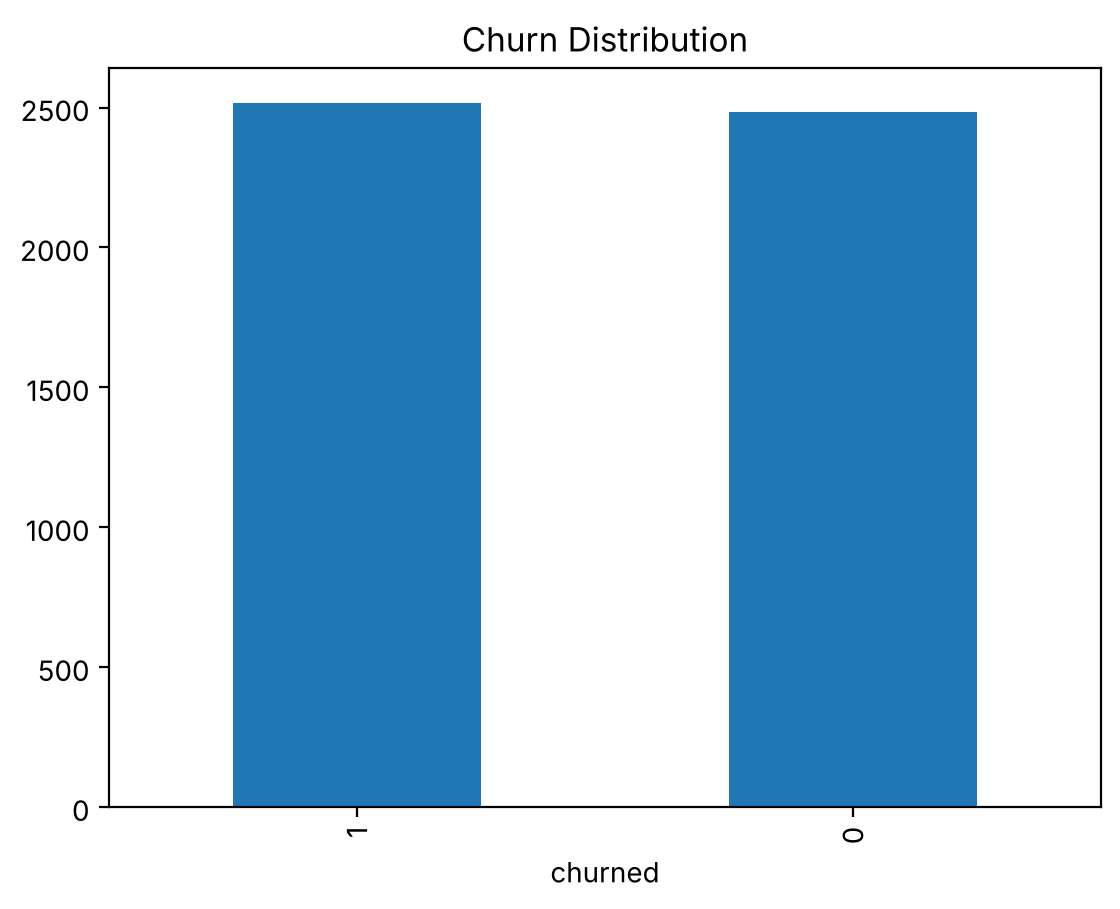

In [5]:
# Basic EDA
print(f"\nChurn rate: {df['churned'].mean():.3f}")
df['churned'].value_counts().plot(kind='bar', title='Churn Distribution')
plt.show()


== Descriptive statistics ==
              count      mean        std    min      25%    50%    75%     max
age          5000.0  43.84740  15.501128  18.00  30.0000  44.00  58.00   70.00
watch_hours  5000.0  11.64945  12.014654   0.01   3.3375   8.00  16.03  110.40
monthly_fee  5000.0  13.68340   3.692062   8.99   8.9900  13.99  17.99   17.99


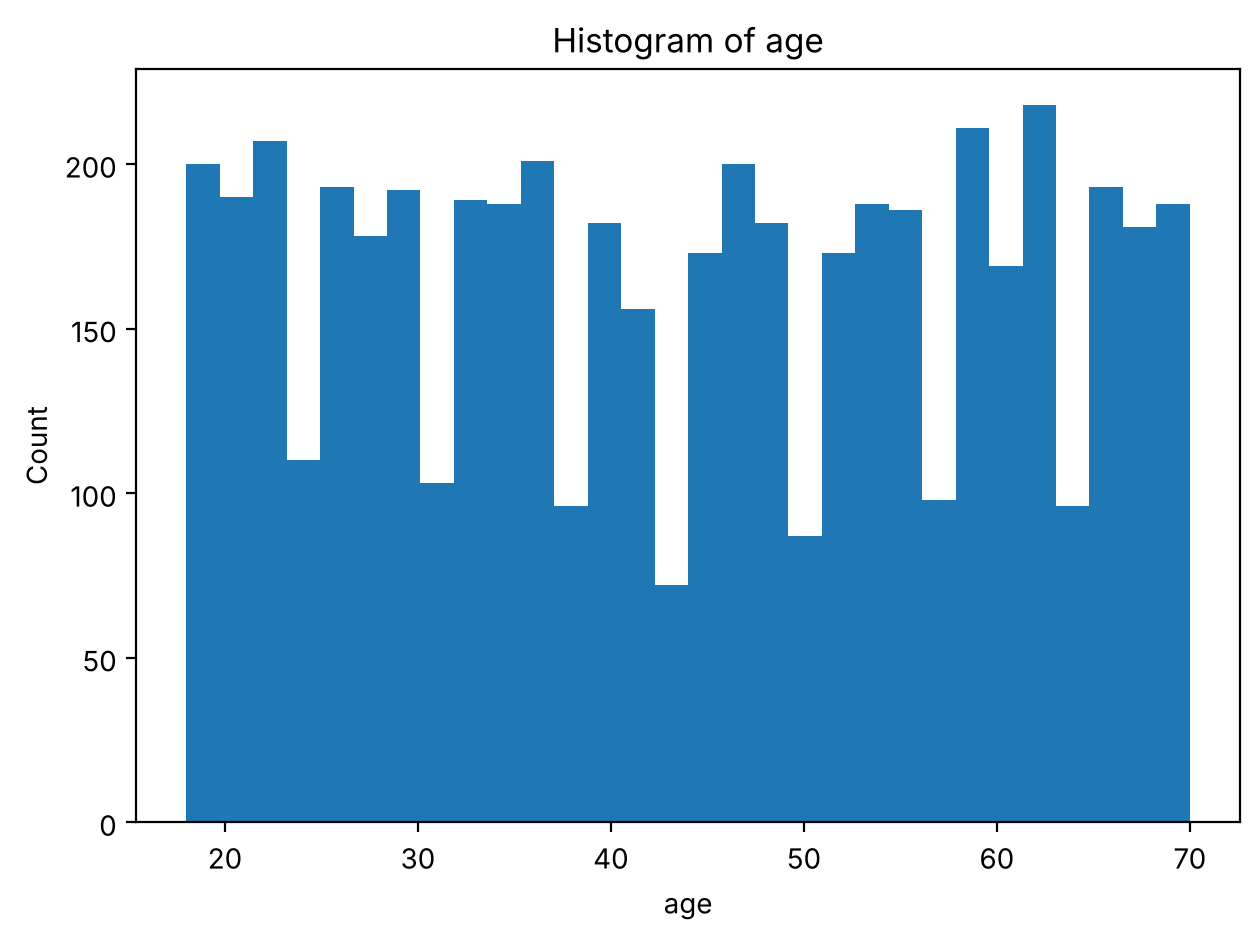

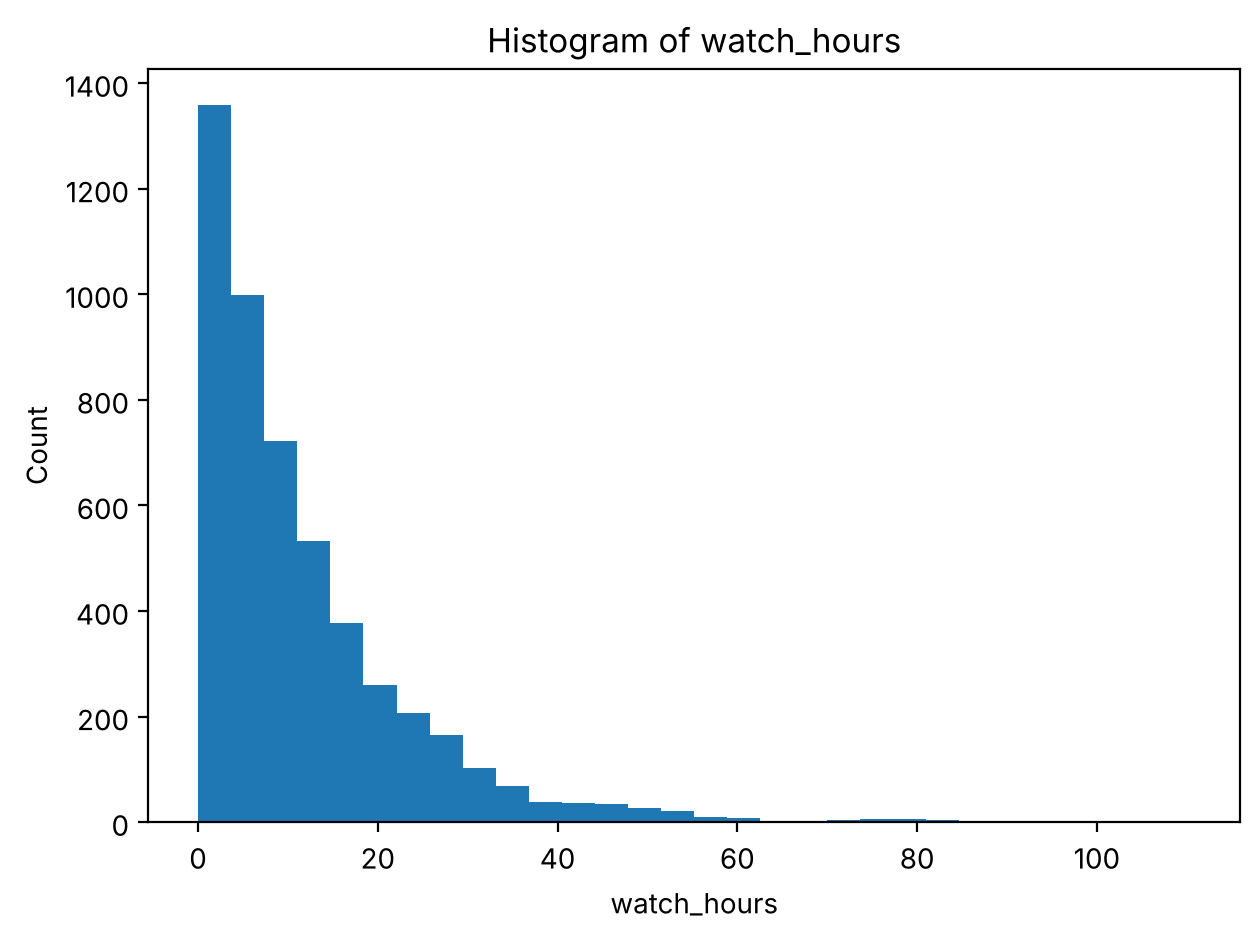

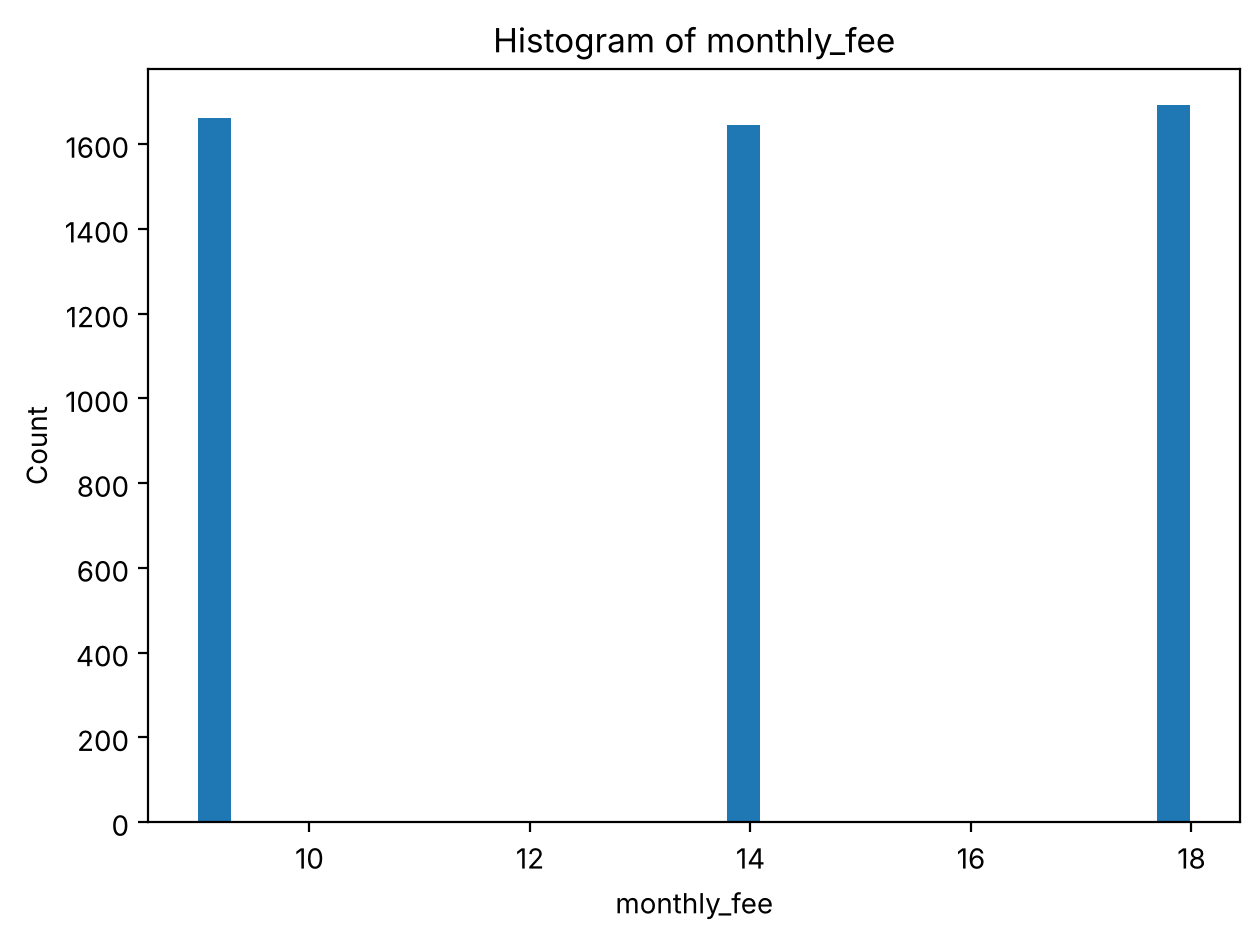

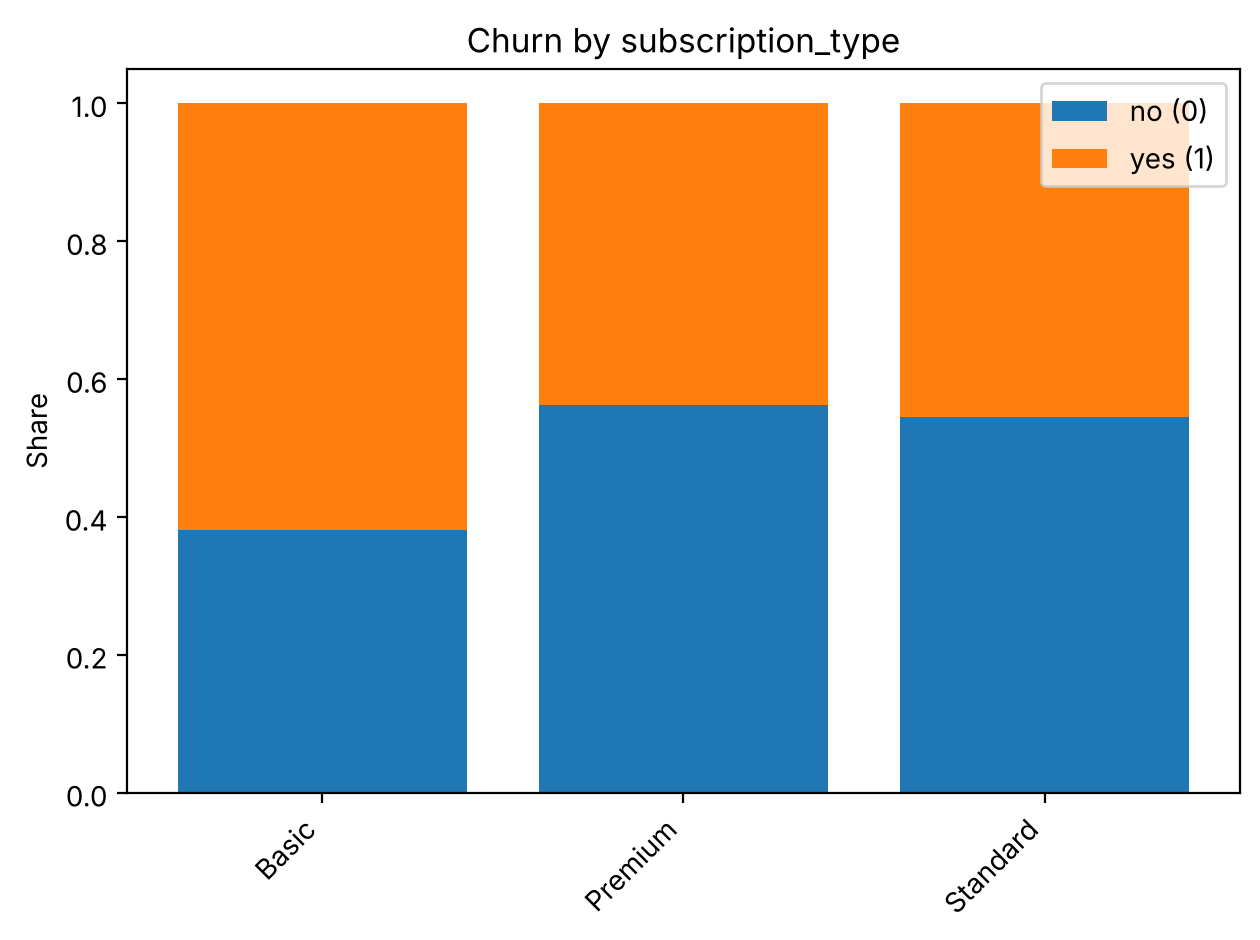

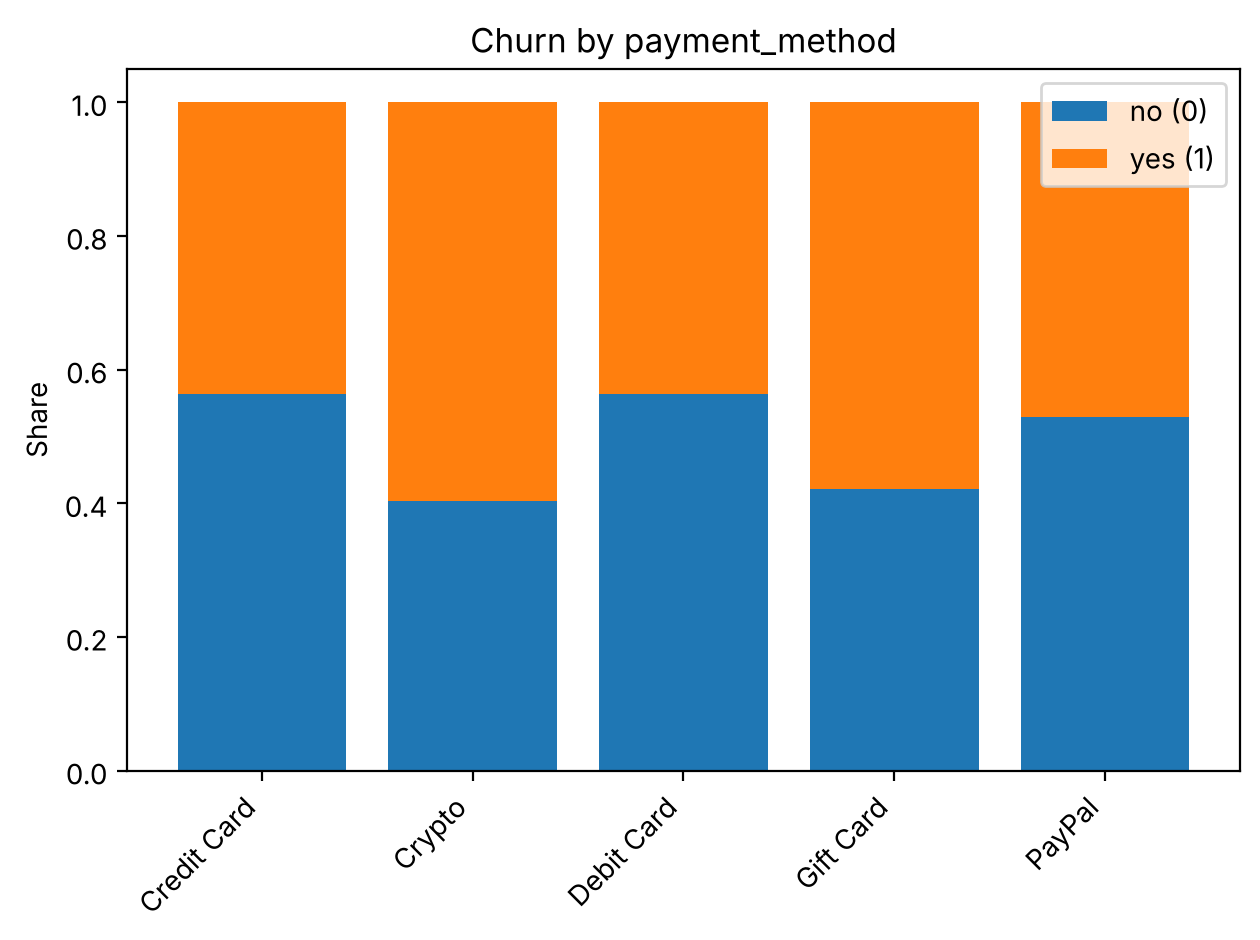

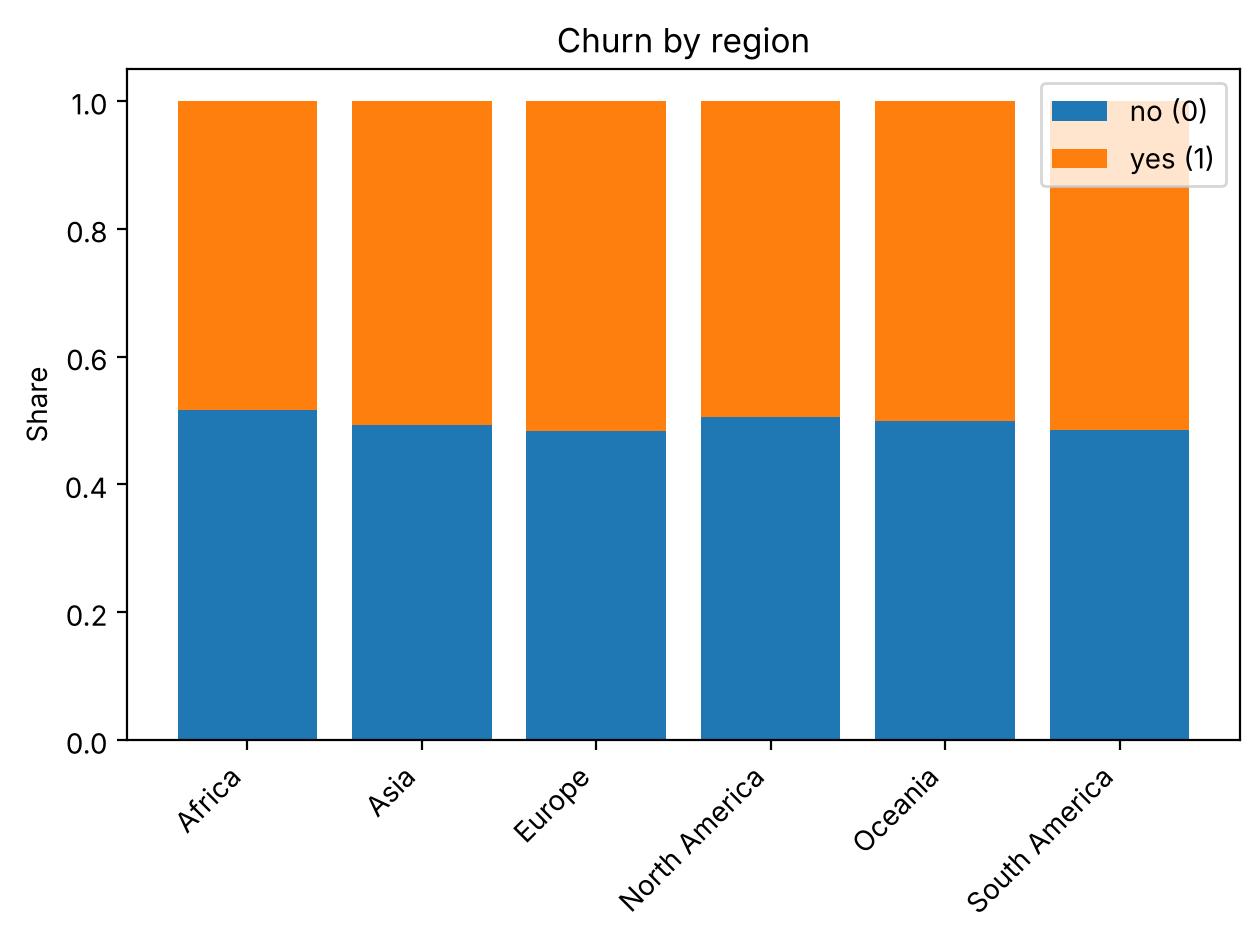

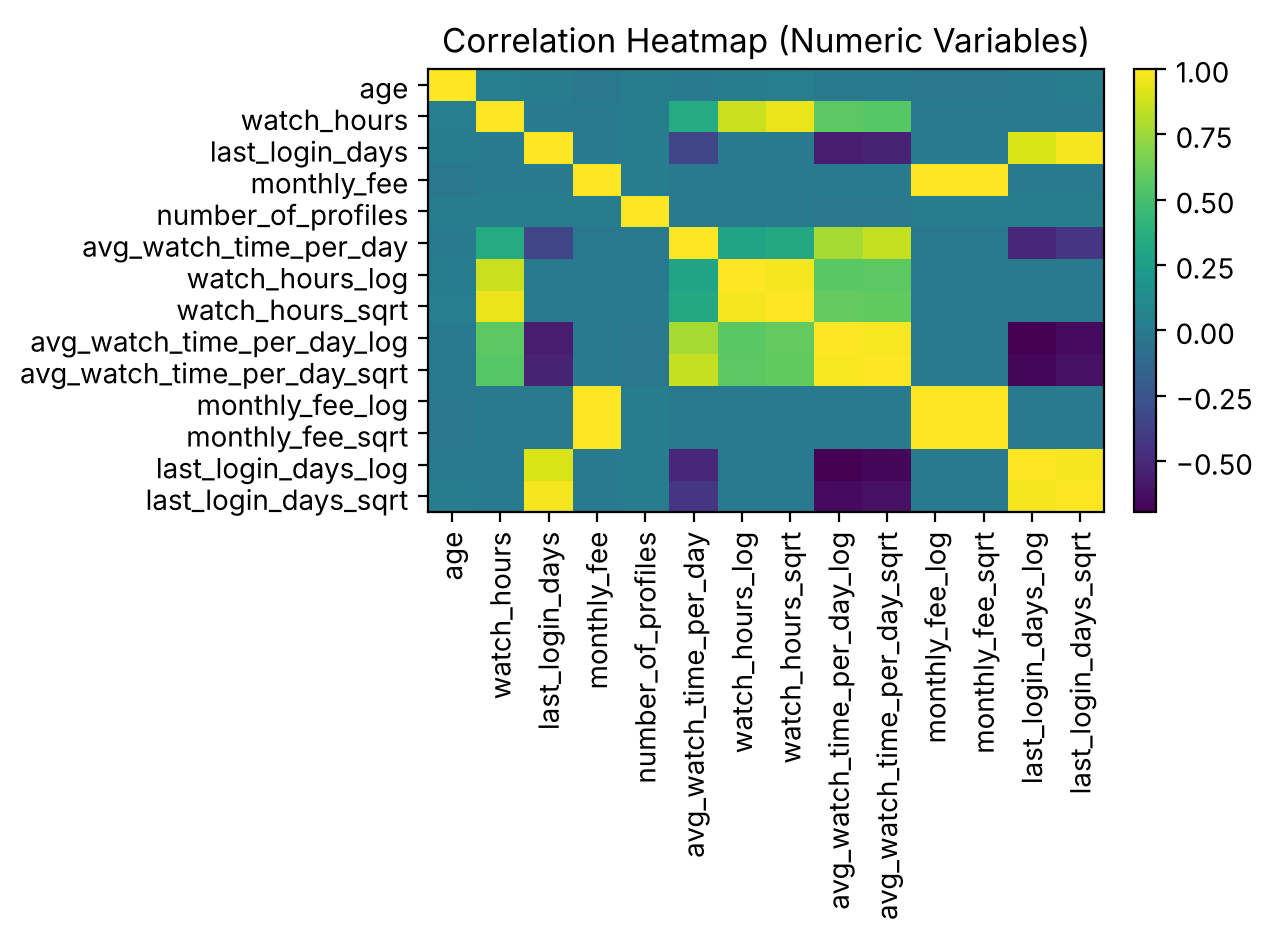

In [6]:
# ----------------- Univariate -----------------
def eda_univariate(df: pd.DataFrame):
    cols = [c for c in ["age", "watch_hours", "monthly_fee"] if c in df.columns]
    if cols:
        print("\n== Descriptive statistics ==")
        print(df[cols].describe().T)

    for c in cols:
        plt.figure()
        plt.hist(df[c].dropna(), bins=30)
        plt.title(f"Histogram of {c}")
        plt.xlabel(c); plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

# ----------------- Bivariate -----------------
def _stacked_share_bar(df, cat_col, target="churned"):
    if (cat_col not in df.columns) or (target not in df.columns):
        print(f"Skip {cat_col}: missing column."); return
    if not set(df[target].dropna().unique()).issubset({0,1}):
        print(f"Skip {cat_col}: target '{target}' not binary 0/1."); return

    ct = pd.crosstab(df[cat_col], df[target], normalize="index")
    labels = ct.index.astype(str).tolist()
    y0 = ct.get(0, pd.Series(0, index=ct.index)).values
    y1 = ct.get(1, pd.Series(0, index=ct.index)).values

    x = np.arange(len(labels))
    plt.figure()
    plt.bar(x, y0, label="no (0)")
    plt.bar(x, y1, bottom=y0, label="yes (1)")
    plt.xticks(x, labels, rotation=45, ha="right")
    plt.ylabel("Share")
    plt.title(f"Churn by {cat_col}")
    plt.legend()
    plt.tight_layout()
    plt.show()

def eda_bivariate(df: pd.DataFrame):
    for col in ["subscription_type", "payment_method", "region"]:
        _stacked_share_bar(df, col, target="churned")

# ----------------- Correlation -----------------
def eda_correlation_heatmap(df: pd.DataFrame):
    num_df = df.select_dtypes(include="number").copy()
    for drop in ["customer_id", "churned"]:
        if drop in num_df.columns:
            num_df = num_df.drop(columns=[drop])
    if num_df.shape[1] < 2:
        print("Not enough numeric columns for correlation heatmap."); return

    corr = num_df.corr(numeric_only=True)
    plt.figure()
    im = plt.imshow(corr.values, aspect="auto")
    plt.xticks(range(corr.shape[1]), corr.columns, rotation=90)
    plt.yticks(range(corr.shape[0]), corr.index)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.title("Correlation Heatmap (Numeric Variables)")
    plt.tight_layout()
    plt.show()

# ===== Run EDA =====
eda_univariate(df)
eda_bivariate(df)
eda_correlation_heatmap(df)


STATISTICAL ANALYSIS & HYPOTHESIS TESTING

RQ1: Behavioral Variables vs Churn
----------------------------------------
watch_hours               r=-0.4799 [-0.5010, -0.4583], p=0.0000 -> Reject H0 (Medium)
avg_watch_time_per_day    r=-0.2730 [-0.2984, -0.2471], p=0.0000 -> Reject H0 (Small)
last_login_days           r=0.4716 [0.4497, 0.4929], p=0.0000 -> Reject H0 (Medium)

RQ2: Subscription & Payment Variables vs Churn
--------------------------------------------------
subscription_type         χ²=133.28, p=0.0000, V=0.1633 -> Reject H0 (Small)
payment_method            χ²=96.91, p=0.0000, V=0.1392 -> Reject H0 (Small)

RQ3: Demographics & Regional Variables vs Churn
--------------------------------------------------
Age                      t=0.249, p=0.8037, d=0.007 -> Fail to reject H0 (Negligible)
gender                    χ²=0.65, p=0.7225, V=0.0114 -> Fail to reject H0 (Negligible)
region                    χ²=2.65, p=0.7531, V=0.0230 -> Fail to reject H0 (Negligible)

HYPOTHES

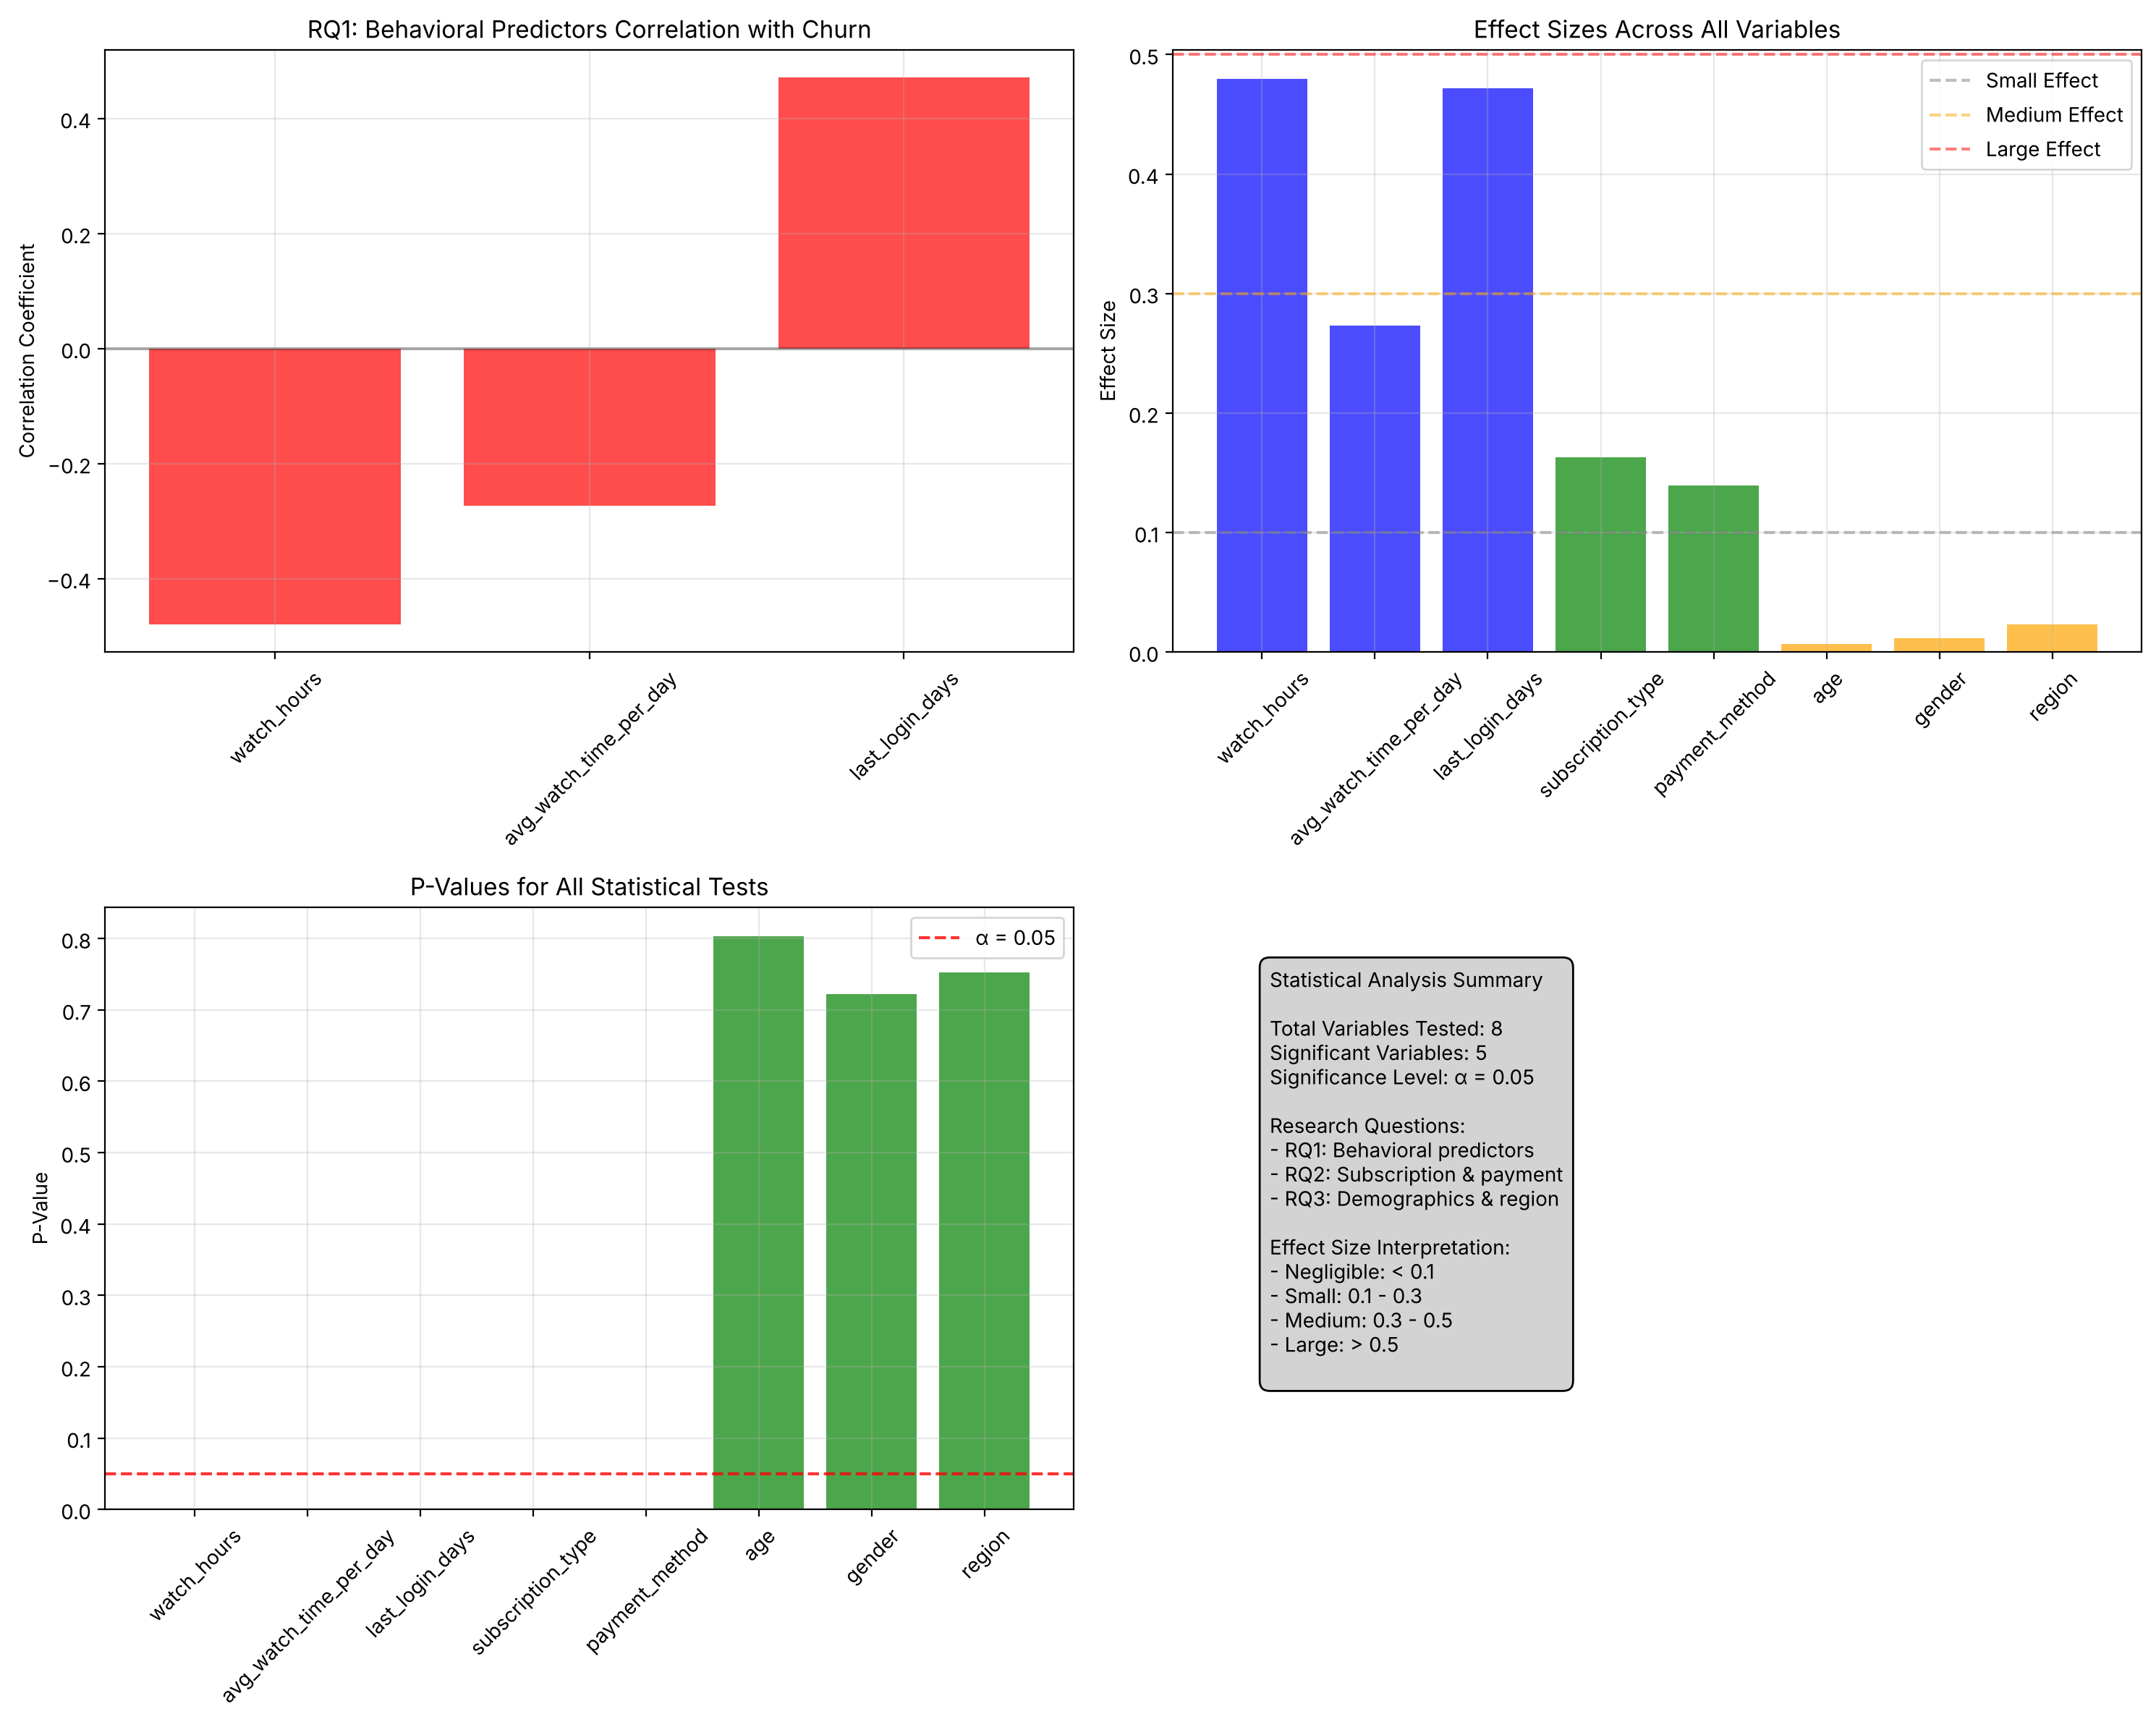


Statistical analysis complete. Results saved to '../outputs/statistical_analysis_results.json'


In [7]:
import os
os.makedirs('../outputs', exist_ok=True)
# Statistical Hypothesis Testing
print("\n" + "="*60)
print("STATISTICAL ANALYSIS & HYPOTHESIS TESTING")
print("="*60)

alpha = 0.05
statistical_results = {}

# RQ1: Behavioral predictors (Point-biserial correlation)
print("\nRQ1: Behavioral Variables vs Churn")
print("-" * 40)
behavioral_vars = ['watch_hours', 'avg_watch_time_per_day', 'last_login_days']
rq1_results = {}

for var in behavioral_vars:
    if var in df.columns:
        # Point-biserial correlation
        r, p = pearsonr(df[var].astype(float), df['churned'].astype(int))
        
        # Calculate confidence interval for correlation
        n = len(df[var].dropna())
        z_r = 0.5 * np.log((1 + r) / (1 - r))
        se = 1 / np.sqrt(n - 3)
        z_025 = 1.96
        ci_lower = np.tanh(z_r - z_025 * se)
        ci_upper = np.tanh(z_r + z_025 * se)
        
        # Effect size interpretation
        effect = abs(r)
        if effect < 0.1:
            effect_label = 'Negligible'
        elif effect < 0.3:
            effect_label = 'Small'
        elif effect < 0.5:
            effect_label = 'Medium'
        else:
            effect_label = 'Large'
        
        decision = "Reject H0" if p < alpha else "Fail to reject H0"
        conclusion = f"{var} significantly predicts churn" if p < alpha else f"{var} does not significantly predict churn"
        
        rq1_results[var] = {
            'correlation': r,
            'p_value': p,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper,
            'effect_size': effect,
            'effect_label': effect_label,
            'decision': decision,
            'conclusion': conclusion
        }
        
        print(f"{var:<25} r={r:.4f} [{ci_lower:.4f}, {ci_upper:.4f}], p={p:.4f} -> {decision} ({effect_label})")

statistical_results['RQ1'] = rq1_results

# RQ2: Subscription & Payment effects (Chi-square tests)
print("\nRQ2: Subscription & Payment Variables vs Churn")
print("-" * 50)
categorical_vars = ['subscription_type', 'payment_method']
rq2_results = {}

for var in categorical_vars:
    if var in df.columns:
        # Create contingency table
        ct = pd.crosstab(df[var], df['churned'])
        
        # Chi-square test
        chi2, p, dof, expected = chi2_contingency(ct)
        n = ct.sum().sum()
        
        # Cramér's V (effect size)
        cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
        
        # Effect size interpretation
        if cramers_v < 0.1:
            effect_label = 'Negligible'
        elif cramers_v < 0.3:
            effect_label = 'Small'
        elif cramers_v < 0.5:
            effect_label = 'Medium'
        else:
            effect_label = 'Large'
        
        decision = "Reject H0" if p < alpha else "Fail to reject H0"
        conclusion = f"{var} significantly affects churn" if p < alpha else f"{var} does not significantly affect churn"
        
        rq2_results[var] = {
            'chi2_statistic': chi2,
            'p_value': p,
            'degrees_of_freedom': dof,
            'cramers_v': cramers_v,
            'effect_label': effect_label,
            'decision': decision,
            'conclusion': conclusion
        }
        
        print(f"{var:<25} χ²={chi2:.2f}, p={p:.4f}, V={cramers_v:.4f} -> {decision} ({effect_label})")

statistical_results['RQ2'] = rq2_results

# RQ3: Demographics analysis
print("\nRQ3: Demographics & Regional Variables vs Churn")
print("-" * 50)
rq3_results = {}

# Age analysis (Independent t-test)
if 'age' in df.columns:
    retained_ages = df[df['churned'] == 0]['age'].dropna()
    churned_ages = df[df['churned'] == 1]['age'].dropna()
    
    # Welch's t-test (unequal variances)
    t_stat, p = ttest_ind(retained_ages, churned_ages, equal_var=False)
    
    # Cohen's d (effect size)
    pooled_std = np.sqrt(((len(retained_ages) - 1) * retained_ages.var() + 
                         (len(churned_ages) - 1) * churned_ages.var()) / 
                        (len(retained_ages) + len(churned_ages) - 2))
    cohens_d = abs(retained_ages.mean() - churned_ages.mean()) / pooled_std
    
    # Effect size interpretation
    if cohens_d < 0.2:
        effect_label = 'Negligible'
    elif cohens_d < 0.5:
        effect_label = 'Small'
    elif cohens_d < 0.8:
        effect_label = 'Medium'
    else:
        effect_label = 'Large'
    
    decision = "Reject H0" if p < alpha else "Fail to reject H0"
    conclusion = "Age significantly affects churn patterns" if p < alpha else "Age does not significantly affect churn patterns"
    
    rq3_results['age'] = {
        't_statistic': t_stat,
        'p_value': p,
        'cohens_d': cohens_d,
        'effect_label': effect_label,
        'decision': decision,
        'conclusion': conclusion,
        'retained_mean': retained_ages.mean(),
        'churned_mean': churned_ages.mean()
    }
    
    print(f"Age                      t={t_stat:.3f}, p={p:.4f}, d={cohens_d:.3f} -> {decision} ({effect_label})")

# Gender and Region analysis (Chi-square tests)
demo_vars = ['gender', 'region']
for var in demo_vars:
    if var in df.columns:
        ct = pd.crosstab(df[var], df['churned'])
        chi2, p, dof, expected = chi2_contingency(ct)
        n = ct.sum().sum()
        cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
        
        if cramers_v < 0.1:
            effect_label = 'Negligible'
        elif cramers_v < 0.3:
            effect_label = 'Small'
        elif cramers_v < 0.5:
            effect_label = 'Medium'
        else:
            effect_label = 'Large'
        
        decision = "Reject H0" if p < alpha else "Fail to reject H0"
        conclusion = f"{var} significantly affects churn patterns" if p < alpha else f"{var} does not significantly affect churn patterns"
        
        rq3_results[var] = {
            'chi2_statistic': chi2,
            'p_value': p,
            'cramers_v': cramers_v,
            'effect_label': effect_label,
            'decision': decision,
            'conclusion': conclusion
        }
        
        print(f"{var:<25} χ²={chi2:.2f}, p={p:.4f}, V={cramers_v:.4f} -> {decision} ({effect_label})")

statistical_results['RQ3'] = rq3_results

# Summary of Statistical Results
print("\n" + "="*60)
print("HYPOTHESIS TESTING SUMMARY")
print("="*60)

significant_predictors = []
for rq, results in statistical_results.items():
    print(f"\n{rq} Results:")
    for var, result in results.items():
        if result['p_value'] < alpha:
            significant_predictors.append(var)
            status = "SIGNIFICANT"
        else:
            status = "NOT SIGNIFICANT"
        print(f"  {var}: {status} (p={result['p_value']:.4f}, Effect: {result['effect_label']})")

print(f"\nSignificant predictors at α = {alpha}: {significant_predictors}")
print(f"Total significant predictors: {len(significant_predictors)}")

# Create statistical results visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Behavioral variables correlation plot
ax1 = axes[0, 0]
if 'RQ1' in statistical_results:
    vars_rq1 = list(statistical_results['RQ1'].keys())
    correlations = [statistical_results['RQ1'][var]['correlation'] for var in vars_rq1]
    p_values = [statistical_results['RQ1'][var]['p_value'] for var in vars_rq1]
    
    colors = ['red' if p < alpha else 'blue' for p in p_values]
    bars = ax1.bar(vars_rq1, correlations, color=colors, alpha=0.7)
    ax1.set_title('RQ1: Behavioral Predictors Correlation with Churn')
    ax1.set_ylabel('Correlation Coefficient')
    ax1.tick_params(axis='x', rotation=45)
    ax1.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax1.grid(True, alpha=0.3)

# 2. Effect sizes comparison
ax2 = axes[0, 1]
all_vars = []
all_effects = []
all_types = []

for rq, results in statistical_results.items():
    for var, result in results.items():
        all_vars.append(var)
        if 'correlation' in result:
            all_effects.append(abs(result['correlation']))
        elif 'cramers_v' in result:
            all_effects.append(result['cramers_v'])
        elif 'cohens_d' in result:
            all_effects.append(result['cohens_d'])
        all_types.append(rq)

colors_by_rq = {'RQ1': 'blue', 'RQ2': 'green', 'RQ3': 'orange'}
colors = [colors_by_rq.get(rq, 'gray') for rq in all_types]

bars = ax2.bar(all_vars, all_effects, color=colors, alpha=0.7)
ax2.set_title('Effect Sizes Across All Variables')
ax2.set_ylabel('Effect Size')
ax2.tick_params(axis='x', rotation=45)
ax2.axhline(y=0.1, color='gray', linestyle='--', alpha=0.5, label='Small Effect')
ax2.axhline(y=0.3, color='orange', linestyle='--', alpha=0.5, label='Medium Effect')
ax2.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Large Effect')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. P-values visualization
ax3 = axes[1, 0]
all_p_values = []
for rq, results in statistical_results.items():
    for var, result in results.items():
        all_p_values.append(result['p_value'])

colors = ['red' if p < alpha else 'green' for p in all_p_values]
bars = ax3.bar(all_vars, all_p_values, color=colors, alpha=0.7)
ax3.set_title('P-Values for All Statistical Tests')
ax3.set_ylabel('P-Value')
ax3.tick_params(axis='x', rotation=45)
ax3.axhline(y=alpha, color='red', linestyle='--', alpha=0.8, label=f'α = {alpha}')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Summary statistics
ax4 = axes[1, 1]
ax4.axis('off')
summary_text = f"""Statistical Analysis Summary

Total Variables Tested: {len(all_vars)}
Significant Variables: {len(significant_predictors)}
Significance Level: α = {alpha}

Research Questions:
- RQ1: Behavioral predictors
- RQ2: Subscription & payment
- RQ3: Demographics & region

Effect Size Interpretation:
- Negligible: < 0.1
- Small: 0.1 - 0.3
- Medium: 0.3 - 0.5
- Large: > 0.5
"""

ax4.text(0.1, 0.9, summary_text, transform=ax4.transAxes, fontsize=10,
         verticalalignment='top', bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray"))

plt.tight_layout()
plt.show()

# Save statistical results
import json
with open('../outputs/statistical_analysis_results.json', 'w') as f:
    json.dump(statistical_results, f, indent=2, default=str)

print("\nStatistical analysis complete. Results saved to '../outputs/statistical_analysis_results.json'")

In [8]:
# Data Preparation
y = df['churned']
X = df.drop(columns=['churned', 'customer_id'])

categorical_features = ['gender', 'subscription_type', 'region', 'device', 'payment_method', 'favorite_genre']
numerical_features = [col for col in X.columns if col not in categorical_features]

In [9]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
# Preprocessing
ohe = OneHotEncoder(drop='first', sparse_output=False)
scaler = StandardScaler()

X_train_cat = ohe.fit_transform(X_train[categorical_features])
X_test_cat = ohe.transform(X_test[categorical_features])

X_train_num = scaler.fit_transform(X_train[numerical_features])
X_test_num = scaler.transform(X_test[numerical_features])

X_train_processed = np.hstack([X_train_cat, X_train_num])
X_test_processed = np.hstack([X_test_cat, X_test_num])

In [11]:
# Feature names for interpretability
feature_names = list(ohe.get_feature_names_out(categorical_features)) + numerical_features

def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    
    print(f"\n{model_name}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
    if y_prob is not None:
        print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
    
    if hasattr(model, 'feature_importances_'):
        importances = pd.DataFrame({
            'feature': feature_names[:len(model.feature_importances_)],
            'importance': model.feature_importances_
        }).sort_values('importance', ascending=False)
        print("Top 5 features:")
        print(importances.head())
    
    return model, y_pred, y_prob

DECISION TREE ANALYSIS

Decision Tree - Default
Confusion Matrix:
 [[484  13]
 [  6 497]]
Accuracy: 0.9810
F1 Score: 0.9812
ROC-AUC: 0.9810
Top 5 features:
                        feature  importance
32  avg_watch_time_per_day_sqrt    0.580160
27           number_of_profiles    0.079581
15     payment_method_Gift Card    0.050079
35          last_login_days_log    0.049925
13        payment_method_Crypto    0.049736

Decision Tree - Entropy
Confusion Matrix:
 [[492   5]
 [  3 500]]
Accuracy: 0.9920
F1 Score: 0.9921
ROC-AUC: 0.9920
Top 5 features:
                        feature  importance
32  avg_watch_time_per_day_sqrt    0.514174
29              watch_hours_log    0.107867
27           number_of_profiles    0.101714
15     payment_method_Gift Card    0.057791
13        payment_method_Crypto    0.051090

Decision Tree - Balanced
Confusion Matrix:
 [[492   5]
 [  4 499]]
Accuracy: 0.9910
F1 Score: 0.9911
ROC-AUC: 0.9910
Top 5 features:
                       feature  importance
31  av

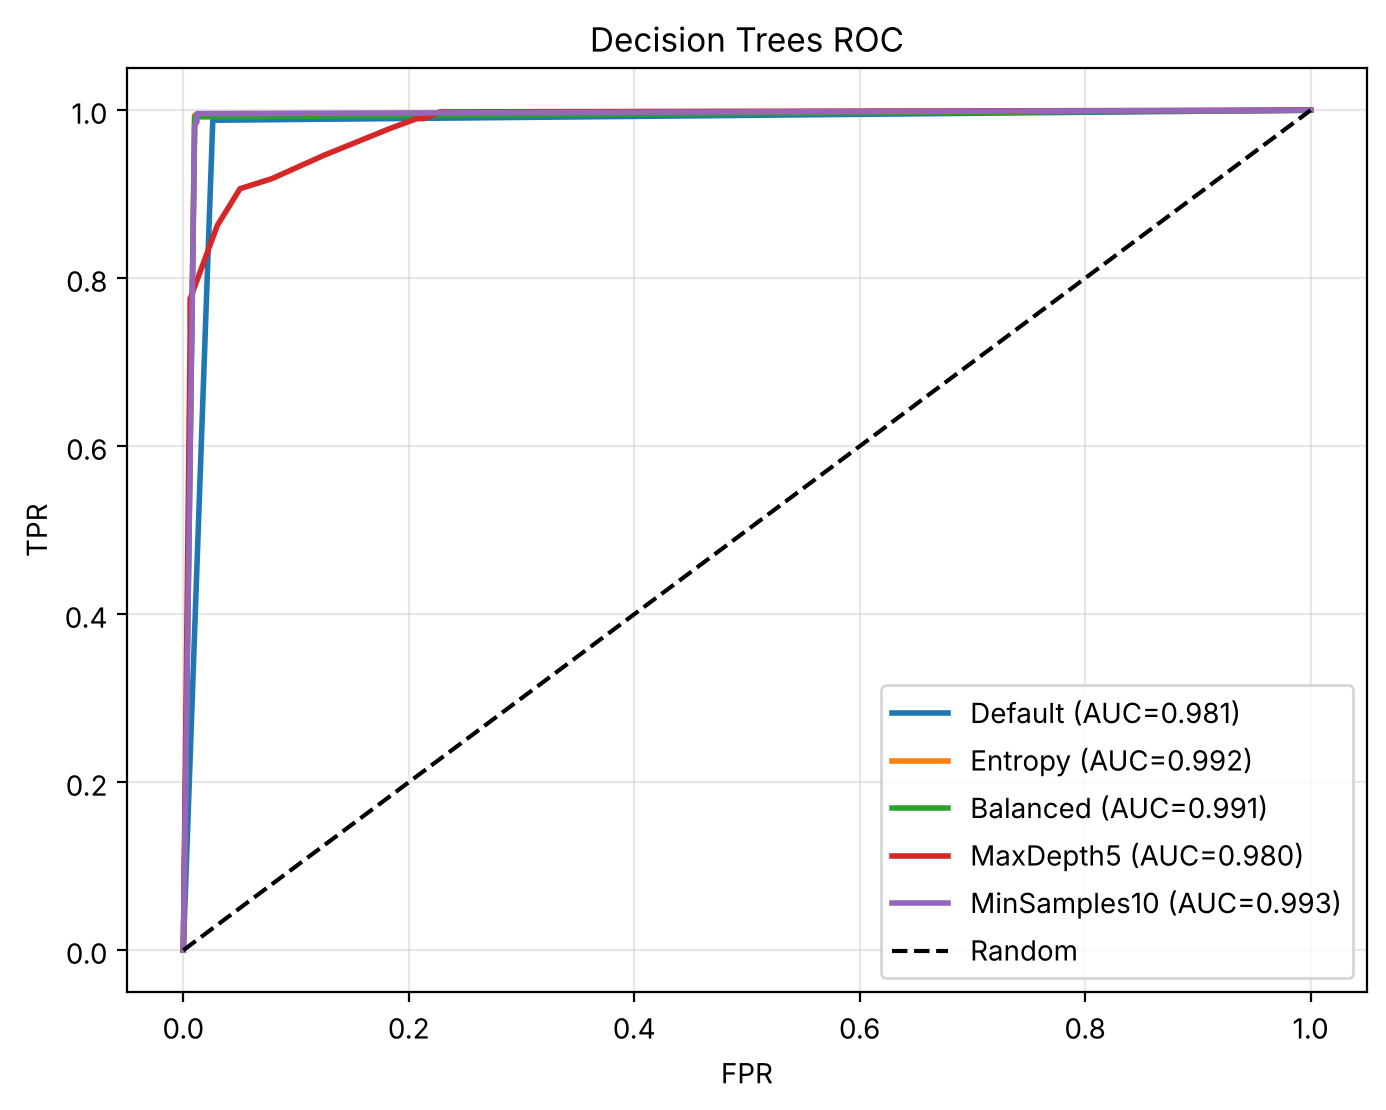

In [12]:
# Decision Tree Models
print("="*50)
print("DECISION TREE ANALYSIS")
print("="*50)

# Default
dt1, _, _ = evaluate_model(DecisionTreeClassifier(random_state=42), 
                          X_train_processed, y_train, X_test_processed, y_test, 
                          "Decision Tree - Default")

# Entropy criterion
dt2, _, _ = evaluate_model(DecisionTreeClassifier(criterion='entropy', random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Decision Tree - Entropy")

# Balanced weights
dt3, _, _ = evaluate_model(DecisionTreeClassifier(criterion='entropy', class_weight='balanced', random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Decision Tree - Balanced")

# Max depth control
dt4, _, _ = evaluate_model(DecisionTreeClassifier(criterion='entropy', class_weight='balanced', max_depth=5, random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Decision Tree - Max Depth 5")

# Min samples split
dt5, _, _ = evaluate_model(DecisionTreeClassifier(criterion='entropy', class_weight='balanced', min_samples_split=10, random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Decision Tree - Min Samples Split 10")
plt.figure(figsize=(8, 6))
dt_models = [(dt1, "Default"), (dt2, "Entropy"), (dt3, "Balanced"), 
             (dt4, "MaxDepth5"), (dt5, "MinSamples10")]

for model, name in dt_models:
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Decision Trees ROC')
plt.legend(); plt.grid(alpha=0.3); plt.show()


RANDOM FOREST ANALYSIS



Random Forest - Default
Confusion Matrix:
 [[491   6]
 [ 11 492]]
Accuracy: 0.9830
F1 Score: 0.9830
ROC-AUC: 0.9978
Top 5 features:
                        feature  importance
31   avg_watch_time_per_day_log    0.156719
32  avg_watch_time_per_day_sqrt    0.144105
28       avg_watch_time_per_day    0.107764
30             watch_hours_sqrt    0.080963
24                  watch_hours    0.075852



Random Forest - Enhanced
Confusion Matrix:
 [[494   3]
 [ 12 491]]
Accuracy: 0.9850
F1 Score: 0.9850
ROC-AUC: 0.9982
Top 5 features:
                        feature  importance
31   avg_watch_time_per_day_log    0.144272
32  avg_watch_time_per_day_sqrt    0.121925
28       avg_watch_time_per_day    0.105160
24                  watch_hours    0.083617
27           number_of_profiles    0.080717



Random Forest - Log2 Features
Confusion Matrix:
 [[492   5]
 [ 11 492]]
Accuracy: 0.9840
F1 Score: 0.9840
ROC-AUC: 0.9976
Top 5 features:
                        feature  importance
31   avg_watch_time_per_day_log    0.132879
32  avg_watch_time_per_day_sqrt    0.126741
28       avg_watch_time_per_day    0.105469
29              watch_hours_log    0.078061
25              last_login_days    0.076823


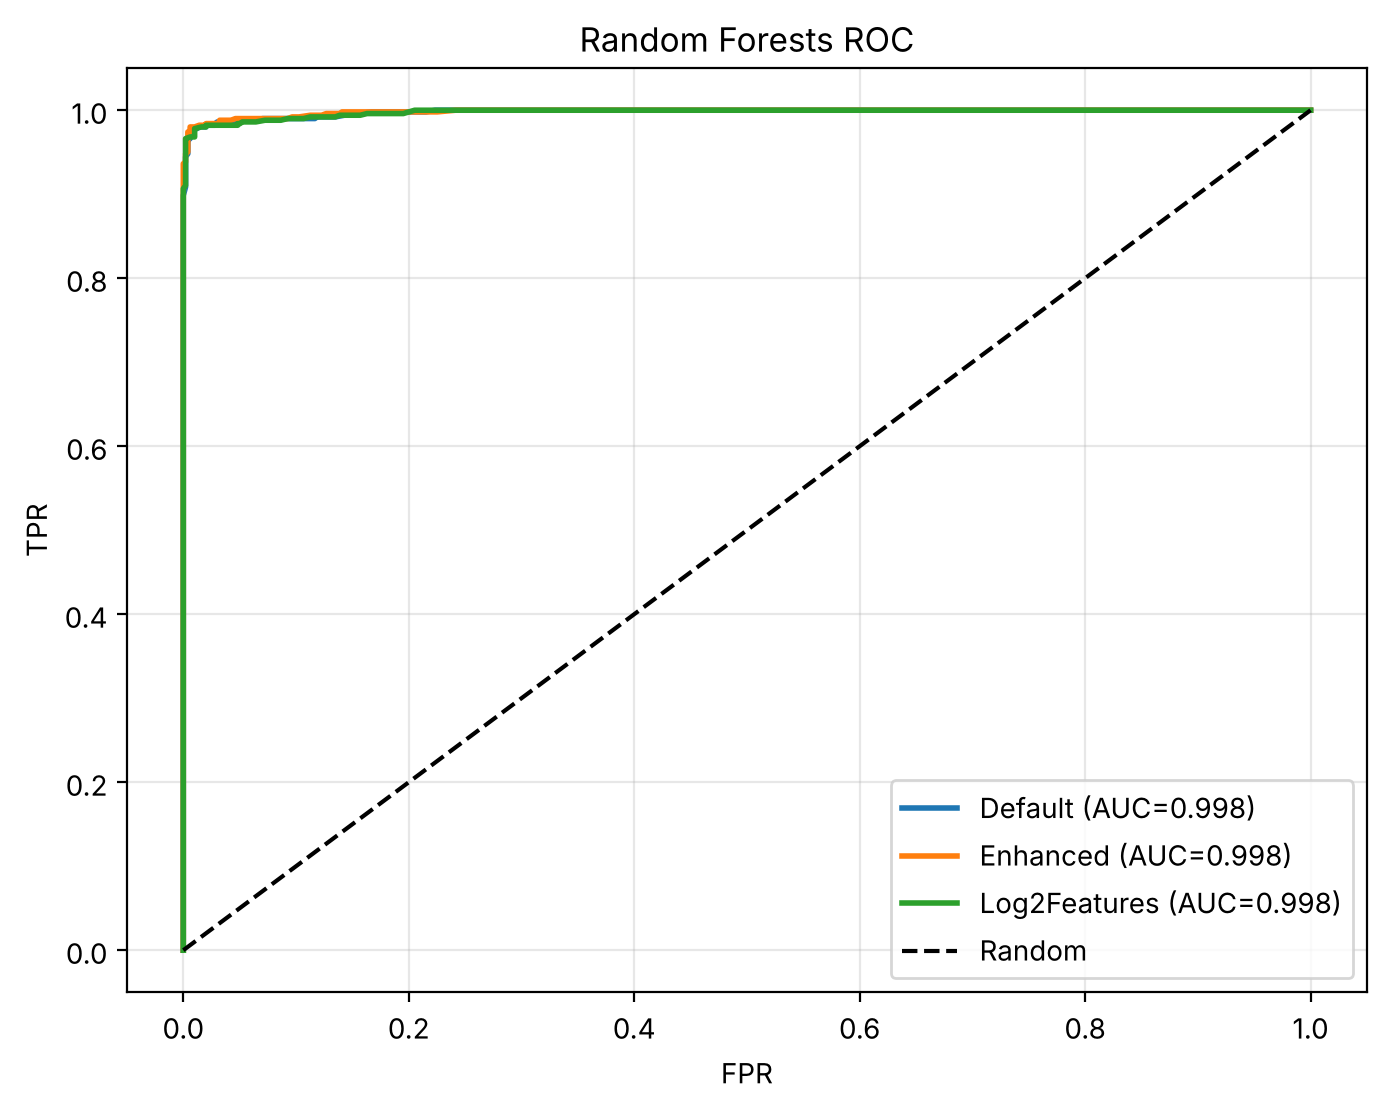

In [13]:
# Random Forest Models
print("\n" + "="*50)
print("RANDOM FOREST ANALYSIS")
print("="*50)

# Default
rf1, _, _ = evaluate_model(RandomForestClassifier(random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Random Forest - Default")

# Enhanced parameters
rf2, _, _ = evaluate_model(RandomForestClassifier(criterion='entropy', class_weight='balanced', random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Random Forest - Enhanced")

# Max features tuning
rf3, _, _ = evaluate_model(RandomForestClassifier(criterion='entropy', class_weight='balanced', max_features='log2', random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Random Forest - Log2 Features")
plt.figure(figsize=(8, 6))
rf_models = [(rf1, "Default"), (rf2, "Enhanced"), (rf3, "Log2Features")]

for model, name in rf_models:
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Random Forests ROC')
plt.legend(); plt.grid(alpha=0.3); plt.show()


GRADIENT BOOSTING ANALYSIS



Gradient Boosting - Default
Confusion Matrix:
 [[491   6]
 [  7 496]]
Accuracy: 0.9870
F1 Score: 0.9871
ROC-AUC: 0.9978
Top 5 features:
                        feature  importance
31   avg_watch_time_per_day_log    0.250477
32  avg_watch_time_per_day_sqrt    0.230416
28       avg_watch_time_per_day    0.164852
27           number_of_profiles    0.084165
36         last_login_days_sqrt    0.043435



Gradient Boosting - Enhanced
Confusion Matrix:
 [[495   2]
 [  6 497]]
Accuracy: 0.9920
F1 Score: 0.9920
ROC-AUC: 0.9988
Top 5 features:
                        feature  importance
31   avg_watch_time_per_day_log    0.248651
32  avg_watch_time_per_day_sqrt    0.228701
28       avg_watch_time_per_day    0.163860
27           number_of_profiles    0.085401
36         last_login_days_sqrt    0.043508


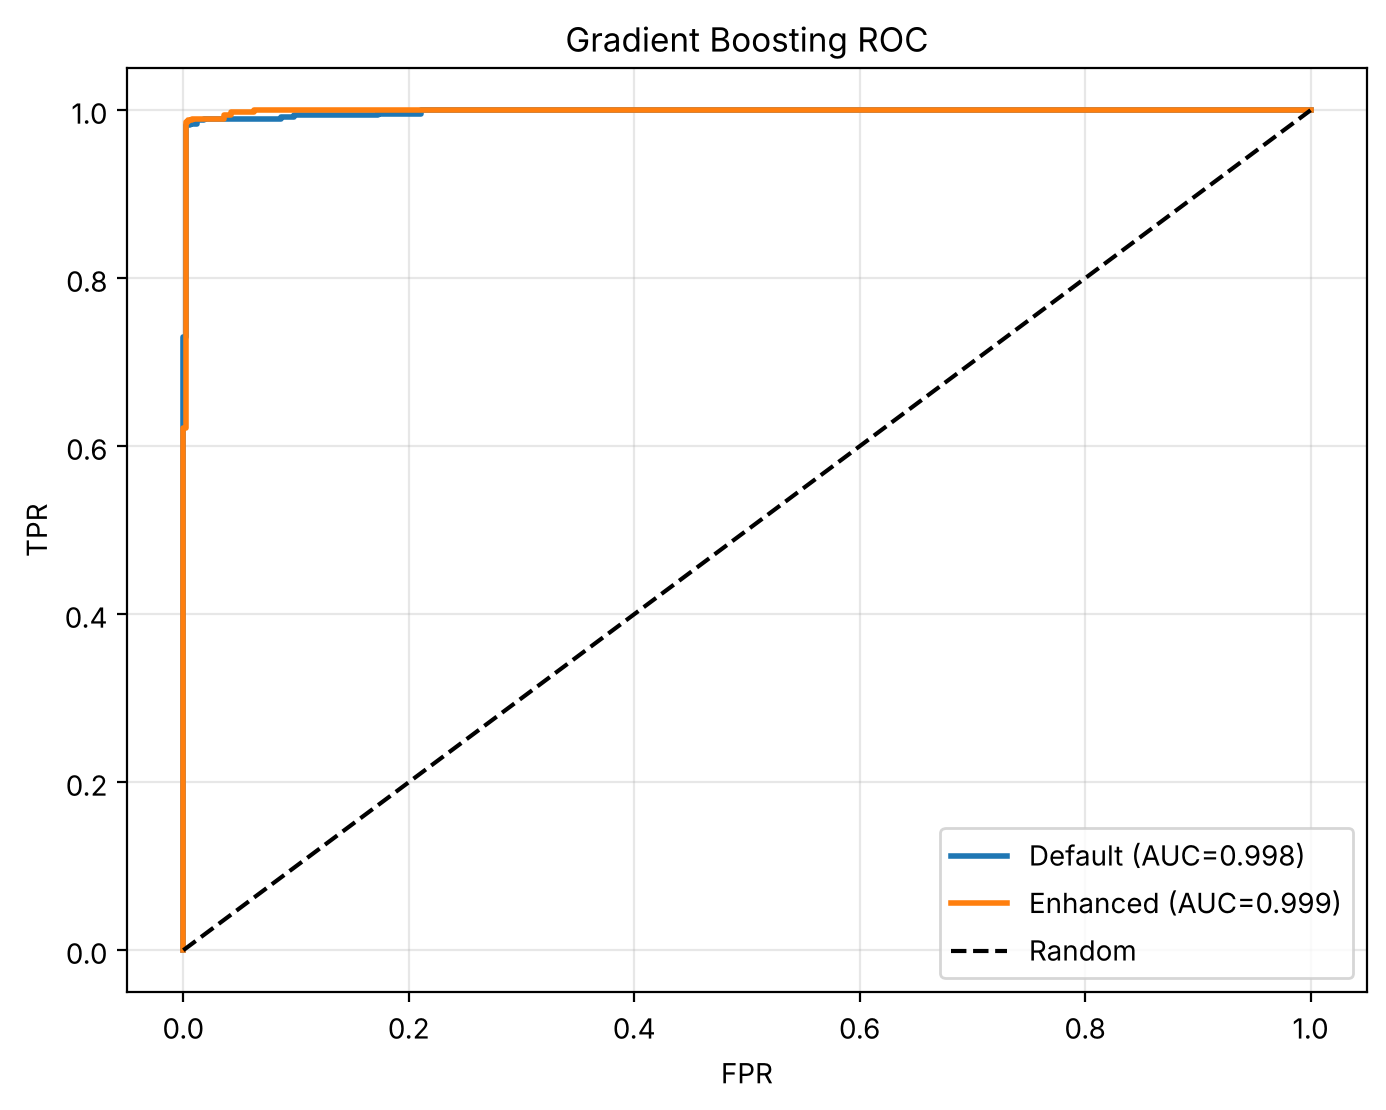

In [14]:
# Gradient Boosting Models
print("\n" + "="*50)
print("GRADIENT BOOSTING ANALYSIS")
print("="*50)

# Default
gb1, _, _ = evaluate_model(GradientBoostingClassifier(random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Gradient Boosting - Default")

# Enhanced parameters
gb2, _, _ = evaluate_model(GradientBoostingClassifier(learning_rate=0.1, n_estimators=200, max_depth=3, random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "Gradient Boosting - Enhanced")
plt.figure(figsize=(8, 6))
gb_models = [(gb1, "Default"), (gb2, "Enhanced")]

for model, name in gb_models:
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Gradient Boosting ROC')
plt.legend(); plt.grid(alpha=0.3); plt.show()


ADDITIONAL MODELS

Logistic Regression
Confusion Matrix:
 [[441  56]
 [ 43 460]]
Accuracy: 0.9010
F1 Score: 0.9028
ROC-AUC: 0.9716



SVM
Confusion Matrix:
 [[450  47]
 [ 33 470]]
Accuracy: 0.9200
F1 Score: 0.9216
ROC-AUC: 0.9809


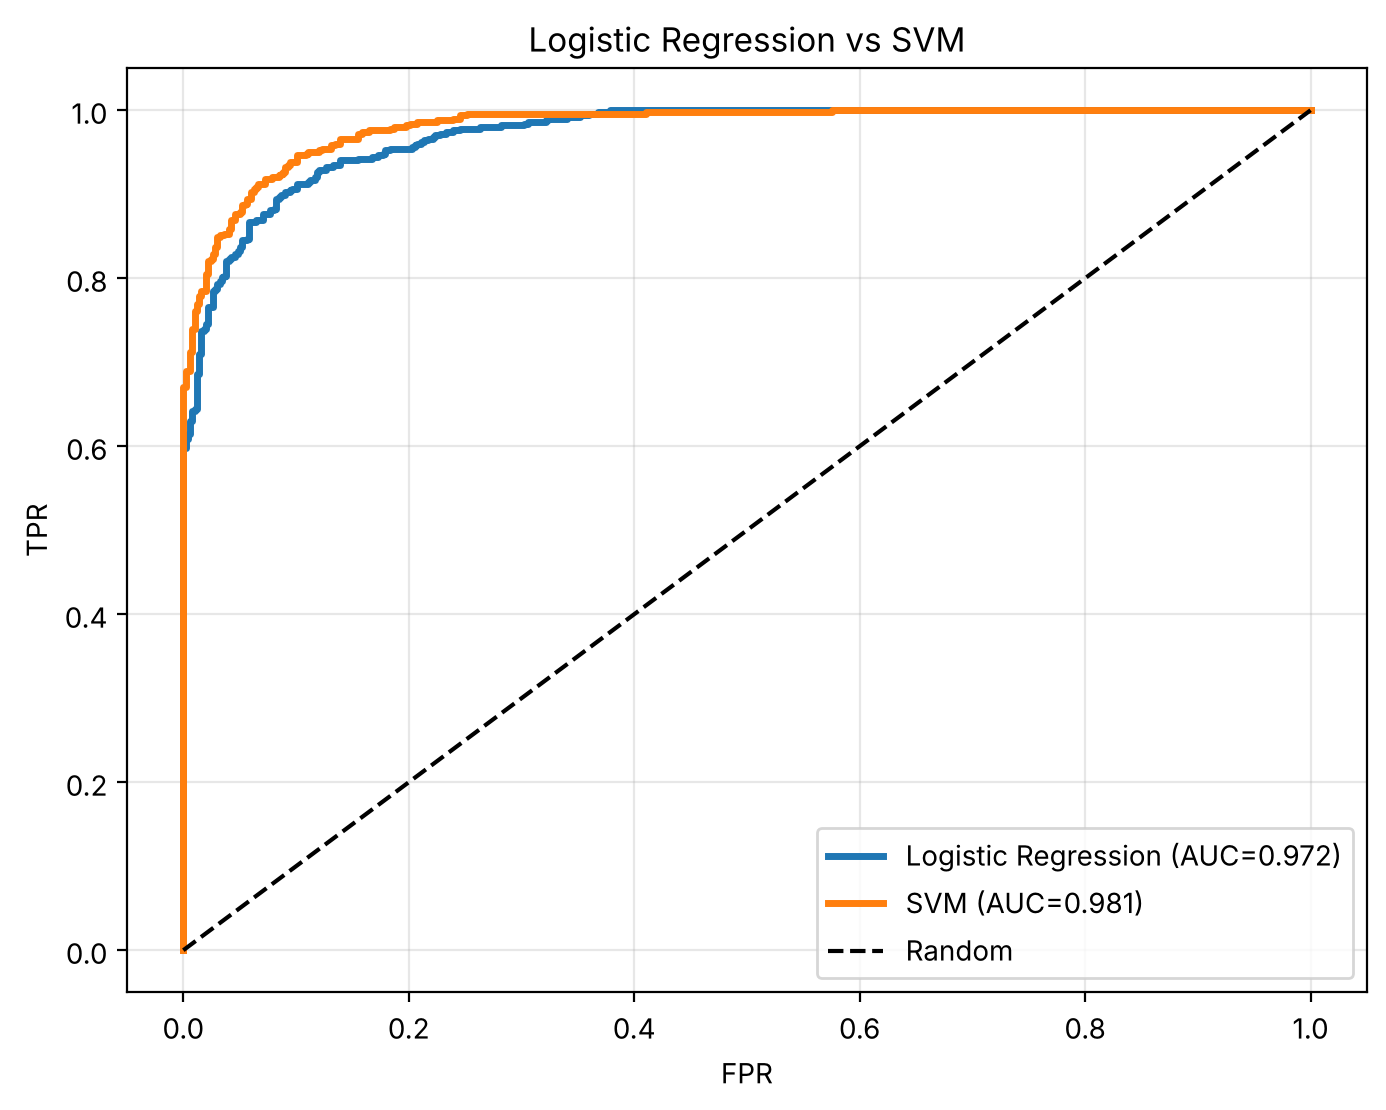

In [15]:
# Additional Models
print("\n" + "="*50)
print("ADDITIONAL MODELS")
print("="*50)

# Logistic Regression
lr, _, _ = evaluate_model(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
                         X_train_processed, y_train, X_test_processed, y_test,
                         "Logistic Regression")

# SVM
svm, _, _ = evaluate_model(SVC(class_weight='balanced', probability=True, random_state=42),
                          X_train_processed, y_train, X_test_processed, y_test,
                          "SVM")
plt.figure(figsize=(8, 6))
models = [(lr, "Logistic Regression"), (svm, "SVM")]

for model, name in models:
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2.5, label=f'{name} (AUC={auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Logistic Regression vs SVM')
plt.legend(); plt.grid(alpha=0.3); plt.show()



MODEL COMPARISON SUMMARY


                               Model  Accuracy     F1  ROC-AUC
        Gradient Boosting - Enhanced    0.9920 0.9920   0.9988
            Random Forest - Enhanced    0.9850 0.9850   0.9982
         Gradient Boosting - Default    0.9870 0.9871   0.9978
             Random Forest - Default    0.9830 0.9830   0.9978
       Random Forest - Log2 Features    0.9840 0.9840   0.9976
Decision Tree - Min Samples Split 10    0.9920 0.9921   0.9929
             Decision Tree - Entropy    0.9920 0.9921   0.9920
            Decision Tree - Balanced    0.9910 0.9911   0.9910
             Decision Tree - Default    0.9810 0.9812   0.9810
                                 SVM    0.9200 0.9216   0.9809
         Decision Tree - Max Depth 5    0.9280 0.9268   0.9804
                 Logistic Regression    0.9010 0.9028   0.9716


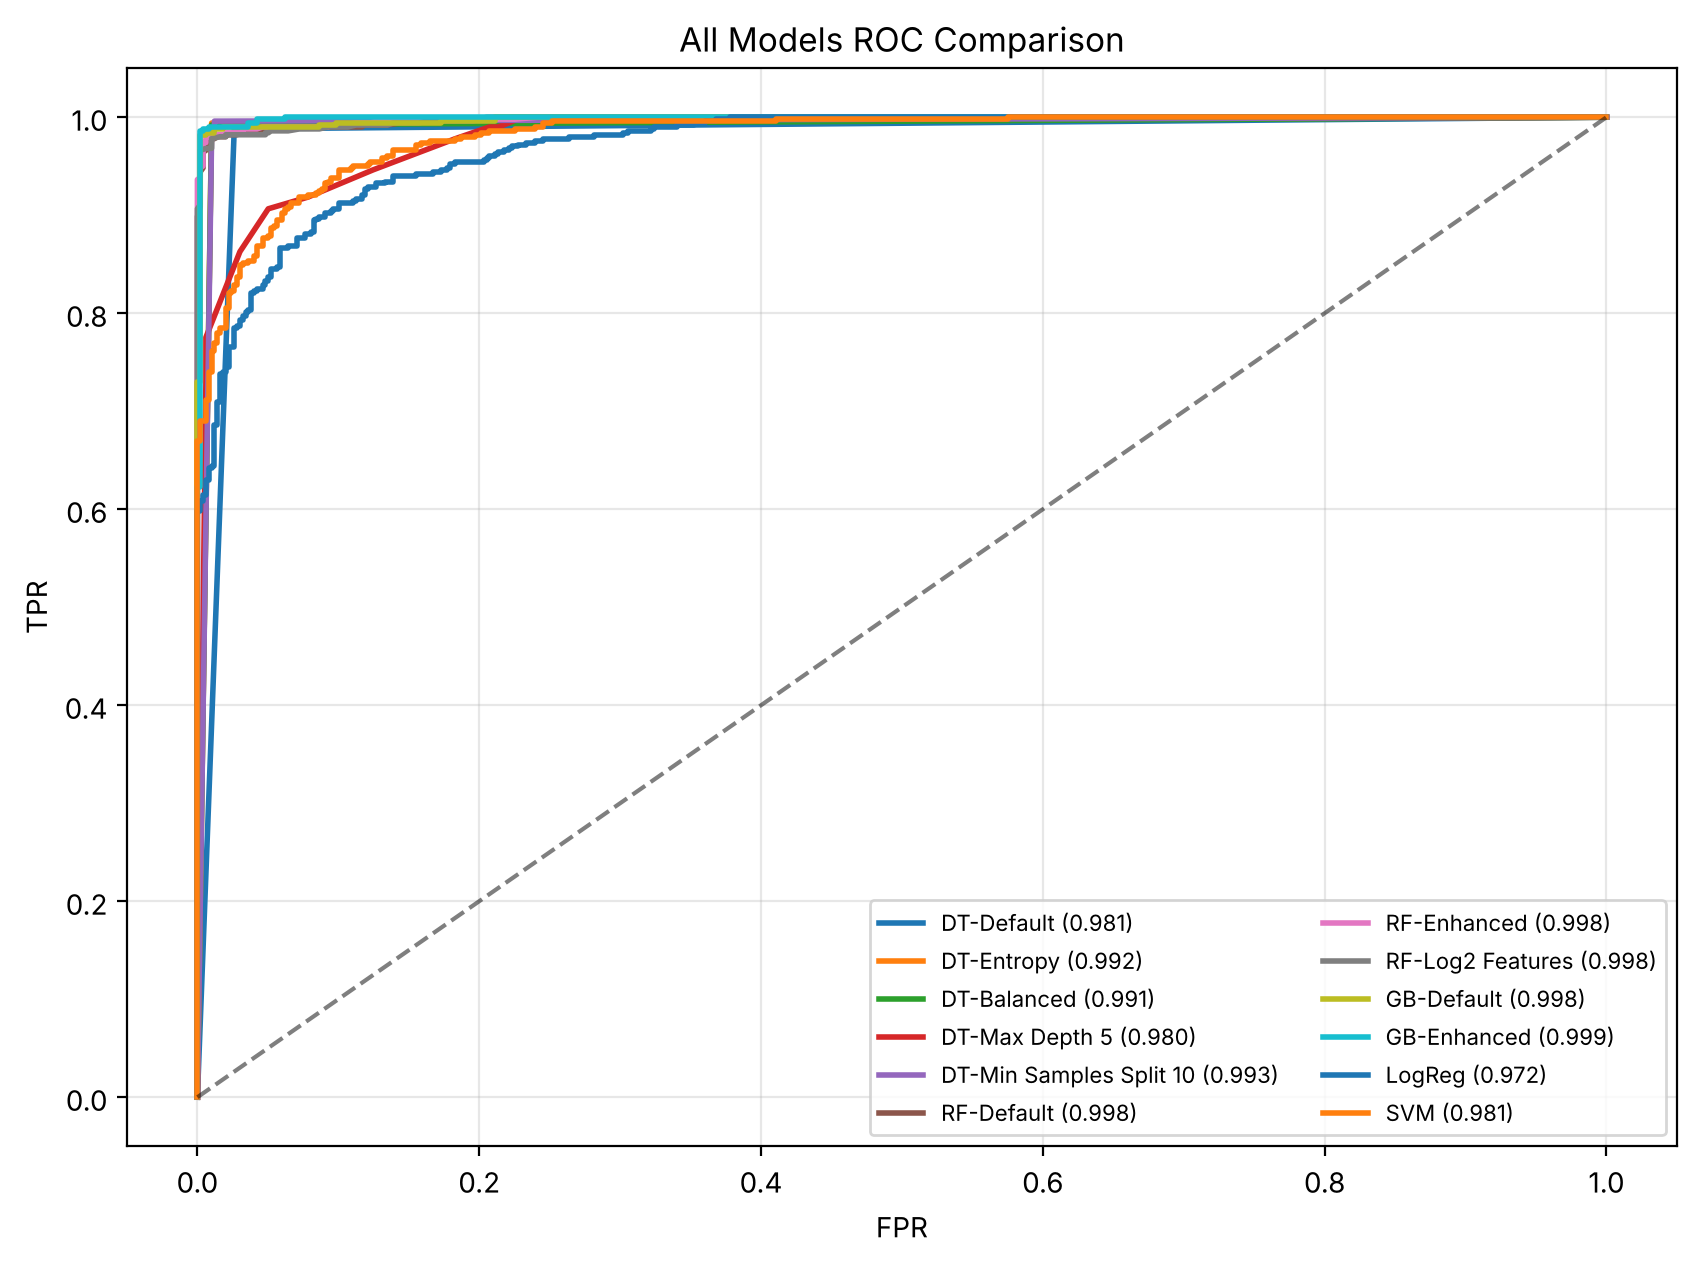


ROC-AUC Ranking:
Gradient Boosting - Enhanced             : 0.9988
Random Forest - Enhanced                 : 0.9982
Gradient Boosting - Default              : 0.9978
Random Forest - Default                  : 0.9978
Random Forest - Log2 Features            : 0.9976
Decision Tree - Min Samples Split 10     : 0.9929
Decision Tree - Entropy                  : 0.9920
Decision Tree - Balanced                 : 0.9910
Decision Tree - Default                  : 0.9810
SVM                                      : 0.9809
Decision Tree - Max Depth 5              : 0.9804
Logistic Regression                      : 0.9716


In [16]:
# Model Comparison
print("\n" + "="*50)
print("MODEL COMPARISON SUMMARY")
print("="*50)

models = [
    ('Decision Tree - Default', dt1),
    ('Decision Tree - Entropy', dt2),
    ('Decision Tree - Balanced', dt3),
    ('Decision Tree - Max Depth 5', dt4),
    ('Decision Tree - Min Samples Split 10', dt5),
    ('Random Forest - Default', rf1),
    ('Random Forest - Enhanced', rf2),
    ('Random Forest - Log2 Features', rf3),
    ('Gradient Boosting - Default', gb1),
    ('Gradient Boosting - Enhanced', gb2),
    ('Logistic Regression', lr),
    ('SVM', svm)
]
results = []
for name, model in models:
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1] if hasattr(model, 'predict_proba') else None
    
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0
    
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'F1': f1,
        'ROC-AUC': roc_auc
    })

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)
print(results_df.to_string(index=False, float_format='%.4f'))

plt.figure(figsize=(10, 7))

# Plot ROC for each model in your results
for name, model in models:
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test_processed)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        # Shorten names for cleaner legend
        short_name = name.replace('Decision Tree - ', 'DT-').replace('Random Forest - ', 'RF-').replace('Gradient Boosting - ', 'GB-').replace('Logistic Regression', 'LogReg')
        plt.plot(fpr, tpr, lw=2, label=f'{short_name} ({auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('All Models ROC Comparison')
plt.legend(loc='lower right', fontsize=8, ncol=2)
plt.grid(alpha=0.3)
plt.show()

# Print sorted AUC scores
print("\nROC-AUC Ranking:")
for item in sorted(results, key=lambda x: x['ROC-AUC'], reverse=True):
    print(f"{item['Model']:40} : {item['ROC-AUC']:.4f}")


In [17]:
# Best Model Analysis
best_model_name = results_df.iloc[0]['Model']
best_model = dict(models)[best_model_name]

print(f"\nBest Model: {best_model_name}")
print(f"ROC-AUC: {results_df.iloc[0]['ROC-AUC']:.4f}")

y_pred_best = best_model.predict(X_test_processed)
y_prob_best = best_model.predict_proba(X_test_processed)[:, 1]




Best Model: Gradient Boosting - Enhanced
ROC-AUC: 0.9988


In [18]:
# Model Validation and Overfitting Analysis
print("\n" + "="*60)
print("MODEL VALIDATION & OVERFITTING ANALYSIS")
print("="*60)

# Cross-validation analysis
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(best_model, X_train_processed, y_train, cv=5, scoring='roc_auc')

print(f"Cross-Validation Analysis:")
print(f"  Mean CV ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"  Test ROC-AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"  Difference: {roc_auc_score(y_test, y_prob_best) - cv_scores.mean():.4f}")

if abs(roc_auc_score(y_test, y_prob_best) - cv_scores.mean()) < 0.02:
    print("  ✓ Model shows good generalization (difference < 2%)")
else:
    print("  ⚠ Potential overfitting detected (difference ≥ 2%)")

# Feature check: identifier and target must not be in the feature set
print(f"\nFeature Check:")
print("-" * 25)
print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
leaky = [c for c in ['customer_id', 'churned'] if c in X.columns]
print(f"  Identifier/target columns in features: {leaky if leaky else 'none'}")

# Baseline model comparison
print(f"\nBaseline Comparison:")
print("-" * 20)
majority_baseline = max(y_test.value_counts()) / len(y_test)
random_baseline = 0.5
print(f"  Majority class baseline: {majority_baseline:.4f}")
print(f"  Random baseline: {random_baseline:.4f}")
print(f"  Our model: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"  Improvement over majority: {roc_auc_score(y_test, y_prob_best) - majority_baseline:.4f}")


MODEL VALIDATION & OVERFITTING ANALYSIS


Cross-Validation Analysis:
  Mean CV ROC-AUC: 0.9990 ± 0.0011
  Test ROC-AUC: 0.9988
  Difference: -0.0002
  ✓ Model shows good generalization (difference < 2%)

Feature Check:
-------------------------
Training set size: 4000
Test set size: 1000
  Identifier/target columns in features: none

Baseline Comparison:
--------------------
  Majority class baseline: 0.5030
  Random baseline: 0.5000
  Our model: 0.9988
  Improvement over majority: 0.4958


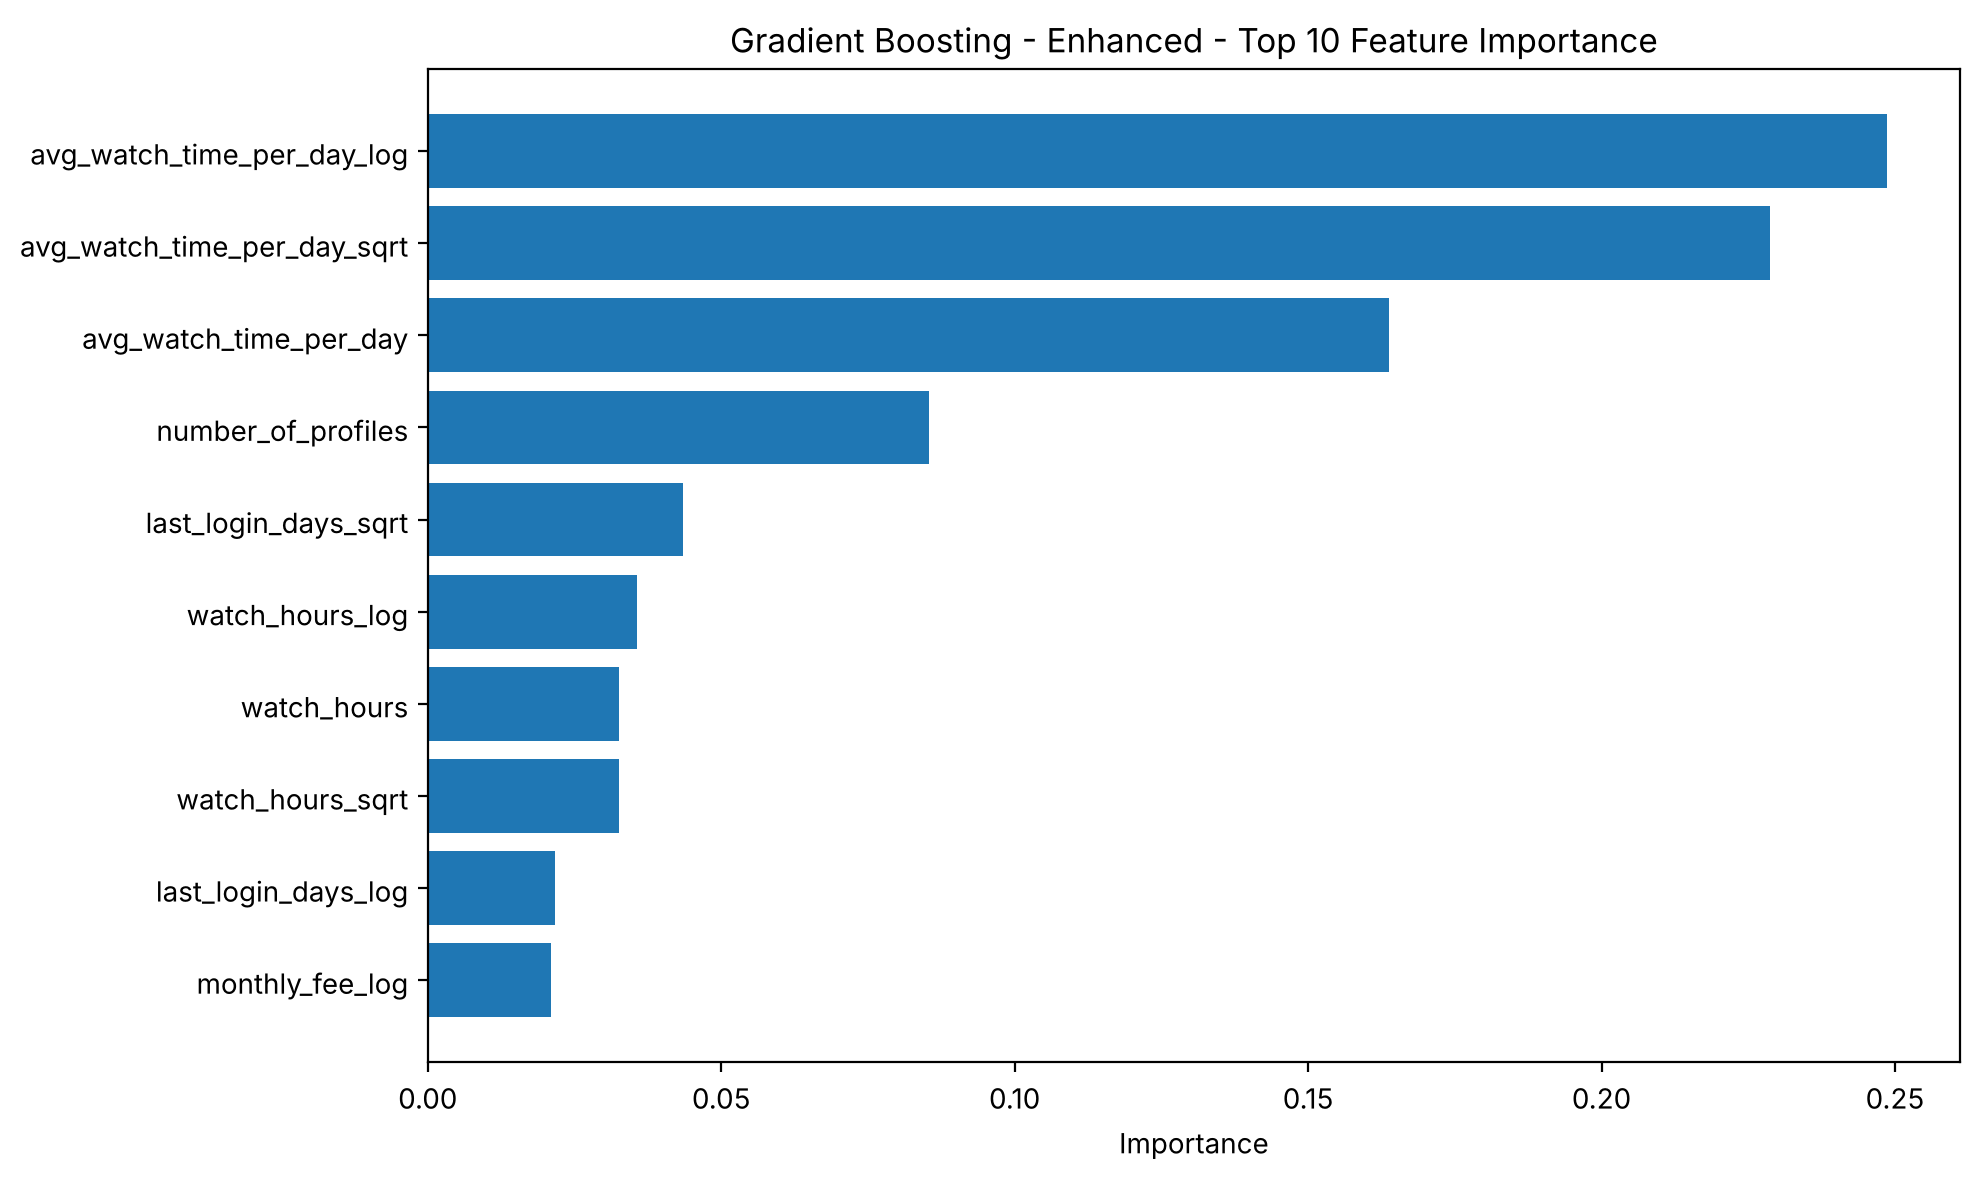

In [19]:
# Feature Importance Visualization
if hasattr(best_model, 'feature_importances_'):
    importances = pd.DataFrame({
        'feature': feature_names[:len(best_model.feature_importances_)],
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False).head(10)
    
    plt.figure(figsize=(10, 6))
    plt.barh(importances['feature'][::-1], importances['importance'][::-1])
    plt.title(f'{best_model_name} - Top 10 Feature Importance')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()

In [20]:
# Advanced Model Interpretability Analysis
print("\n" + "="*60)
print("ADVANCED MODEL INTERPRETABILITY")
print("="*60)

# Analyze prediction patterns
predictions_analysis = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred_best,
    'probability': y_prob_best
})

# Prediction confidence analysis
print("\nPrediction Confidence Analysis:")
print("-" * 35)
confidence_bins = pd.cut(y_prob_best, bins=[0, 0.3, 0.7, 1.0], labels=['Low Confidence', 'Medium Confidence', 'High Confidence'])
confidence_accuracy = predictions_analysis.groupby(confidence_bins).agg({
    'actual': 'count',
    'predicted': lambda x: (predictions_analysis.loc[x.index, 'actual'] == x).sum()
}).round(4)
confidence_accuracy['accuracy'] = confidence_accuracy['predicted'] / confidence_accuracy['actual']

print(confidence_accuracy)

# Decision boundary analysis
print(f"\nDecision Boundary Analysis:")
print("-" * 30)
threshold_analysis = []
for threshold in [0.3, 0.5, 0.7]:
    pred_at_threshold = (y_prob_best >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_at_threshold).ravel()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    threshold_analysis.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'specificity': specificity,
        'f1': 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    })
    
    print(f"Threshold {threshold}: Precision={precision:.3f}, Recall={recall:.3f}, F1={2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0:.3f}")

# Feature interaction analysis (for tree-based models)
if hasattr(best_model, 'feature_importances_'):
    print(f"\nTop Feature Combinations Analysis:")
    print("-" * 40)
    
    # Analyze predictions by top features
    top_features = importances.head(3)['feature'].tolist()
    
    for i, feature in enumerate(top_features[:2]):  # Analyze top 2 features
        feature_idx = feature_names.index(feature) if feature in feature_names else i
        
        if feature_idx < len(X_test.columns):
            feature_values = X_test.iloc[:, feature_idx] if hasattr(X_test, 'iloc') else X_test_processed[:, feature_idx]
            
            # Quartile analysis
            quartiles = np.percentile(feature_values, [25, 50, 75])
            
            for j, (q_name, q_val) in enumerate(zip(['Q1', 'Q2', 'Q3', 'Q4'], [0, quartiles[0], quartiles[1], quartiles[2]])):
                if j == 0:
                    mask = feature_values <= quartiles[0]
                elif j == 1:
                    mask = (feature_values > quartiles[0]) & (feature_values <= quartiles[1])
                elif j == 2:
                    mask = (feature_values > quartiles[1]) & (feature_values <= quartiles[2])
                else:
                    mask = feature_values > quartiles[2]
                
                if mask.sum() > 0:
                    avg_prob = y_prob_best[mask].mean()
                    print(f"  {feature} {q_name}: Avg Churn Prob = {avg_prob:.3f} ({mask.sum()} customers)")


ADVANCED MODEL INTERPRETABILITY

Prediction Confidence Analysis:
-----------------------------------
                   actual  predicted  accuracy
Low Confidence        496        491  0.989919
Medium Confidence       9          7  0.777778
High Confidence       495        494  0.997980

Decision Boundary Analysis:
------------------------------
Threshold 0.3: Precision=0.988, Recall=0.990, F1=0.989
Threshold 0.5: Precision=0.996, Recall=0.988, F1=0.992
Threshold 0.7: Precision=0.998, Recall=0.982, F1=0.990

Top Feature Combinations Analysis:
----------------------------------------


In [21]:
# Business Insights
print("\n" + "="*50)
print("BUSINESS INSIGHTS")
print("="*50)

high_risk_threshold = 0.7
high_risk_customers = (y_prob_best >= high_risk_threshold).sum()
medium_risk_customers = ((y_prob_best >= 0.3) & (y_prob_best < 0.7)).sum()
low_risk_customers = (y_prob_best < 0.3).sum()

print(f"Customer Risk Segmentation:")
print(f"High Risk (≥70%): {high_risk_customers} customers ({high_risk_customers/len(y_test)*100:.1f}%)")
print(f"Medium Risk (30-70%): {medium_risk_customers} customers ({medium_risk_customers/len(y_test)*100:.1f}%)")
print(f"Low Risk (<30%): {low_risk_customers} customers ({low_risk_customers/len(y_test)*100:.1f}%)")


BUSINESS INSIGHTS
Customer Risk Segmentation:
High Risk (≥70%): 495 customers (49.5%)
Medium Risk (30-70%): 9 customers (0.9%)
Low Risk (<30%): 496 customers (49.6%)


In [22]:
# Enhanced Business Impact Analysis
print("\n" + "="*60)
print("ENHANCED BUSINESS IMPACT ANALYSIS")
print("="*60)

# Customer Lifetime Value Analysis
if 'monthly_fee' in df.columns and 'subscription_type' in df.columns:
    print("\nCustomer Lifetime Value Analysis:")
    print("-" * 40)
    
    # Industry benchmarks for streaming services
    industry_params = {
        'avg_customer_lifespan_months': 18,  # Netflix industry average
        'gross_margin': 0.60,  # Netflix's approximate gross margin
        'acquisition_cost_per_customer': 120,  # Industry average
        'retention_campaign_cost': 25,  # Cost per targeted customer
        'campaign_success_rate': 0.15  # 15% of targeted customers retained
    }
    
    clv_analysis = {}
    for subscription in df['subscription_type'].unique():
        subset = df[df['subscription_type'] == subscription]
        avg_fee = subset['monthly_fee'].mean()
        churn_rate = subset['churned'].mean()
        customer_count = len(subset)
        
        # Calculate CLV
        monthly_churn = churn_rate / 12 if churn_rate > 0.1 else churn_rate  # Adjust if annual rate
        customer_lifespan = 1 / max(monthly_churn, 0.01)  # Avoid division by zero
        gross_clv = avg_fee * customer_lifespan * industry_params['gross_margin']
        net_clv = gross_clv - industry_params['acquisition_cost_per_customer']
        
        # High-risk customers for this subscription
        subscription_mask = df['subscription_type'] == subscription
        high_risk_count = int((y_prob_best[subscription_mask.loc[X_test.index]] >= 0.7).sum() if len(X_test) > 0 else 
                             (best_model.predict_proba(X[subscription_mask])[:, 1] >= 0.7).sum())
        
        # Revenue at risk
        revenue_at_risk = high_risk_count * avg_fee * 12  # Annual revenue at risk
        
        clv_analysis[subscription] = {
            'avg_monthly_fee': avg_fee,
            'customer_count': customer_count,
            'churn_rate': churn_rate,
            'customer_lifespan_months': customer_lifespan,
            'gross_clv': gross_clv,
            'net_clv': net_clv,
            'high_risk_customers': high_risk_count,
            'revenue_at_risk': revenue_at_risk
        }
        
        print(f"{subscription}:")
        print(f"  Average Monthly Fee: ${avg_fee:.2f}")
        print(f"  Customer Lifespan: {customer_lifespan:.1f} months")
        print(f"  Gross CLV: ${gross_clv:.2f}")
        print(f"  Net CLV: ${net_clv:.2f}")
        print(f"  High-Risk Customers (test set): {high_risk_count}")
        print(f"  Annual Revenue at Risk: ${revenue_at_risk:,.2f}")

# ROI Analysis for Retention Campaigns
print("\nRetention Campaign ROI Analysis:")
print("-" * 40)

total_high_risk = sum([clv_analysis[sub]['high_risk_customers'] for sub in clv_analysis.keys()])
total_campaign_cost = total_high_risk * industry_params['retention_campaign_cost']
customers_retained = total_high_risk * industry_params['campaign_success_rate']

# Calculate weighted average CLV
weighted_clv = sum([data['net_clv'] * data['customer_count'] for data in clv_analysis.values()]) / sum([data['customer_count'] for data in clv_analysis.values()])
total_benefit = customers_retained * weighted_clv
net_roi = ((total_benefit - total_campaign_cost) / total_campaign_cost) * 100

print(f"Total High-Risk Customers: {total_high_risk}")
print(f"Campaign Cost: ${total_campaign_cost:,.2f}")
print(f"Expected Customers Retained: {customers_retained:.0f}")
print(f"Expected Benefit: ${total_benefit:,.2f}")
print(f"Net ROI: {net_roi:.1f}%")

# Sensitivity Analysis
print(f"\nSensitivity Analysis:")
success_rates = [0.10, 0.15, 0.20, 0.25, 0.30]
for rate in success_rates:
    retained = total_high_risk * rate
    benefit = retained * weighted_clv
    roi = ((benefit - total_campaign_cost) / total_campaign_cost) * 100
    print(f"  Success Rate {rate:.0%}: ROI = {roi:.1f}%")
# Success rate at which the campaign breaks even (benefit = cost)
break_even_rate = industry_params['retention_campaign_cost'] / weighted_clv
print(f"\nBreak-even campaign success rate: {break_even_rate:.1%}")



ENHANCED BUSINESS IMPACT ANALYSIS

Customer Lifetime Value Analysis:
----------------------------------------
Basic:
  Average Monthly Fee: $8.99
  Customer Lifespan: 19.4 months
  Gross CLV: $104.69
  Net CLV: $-15.31
  High-Risk Customers (test set): 213
  Annual Revenue at Risk: $22,978.44
Standard:
  Average Monthly Fee: $13.99
  Customer Lifespan: 26.4 months
  Gross CLV: $221.66
  Net CLV: $101.66
  High-Risk Customers (test set): 153
  Annual Revenue at Risk: $25,685.64
Premium:
  Average Monthly Fee: $17.99
  Customer Lifespan: 27.5 months
  Gross CLV: $296.34
  Net CLV: $176.34
  High-Risk Customers (test set): 129
  Annual Revenue at Risk: $27,848.52

Retention Campaign ROI Analysis:
----------------------------------------
Total High-Risk Customers: 495
Campaign Cost: $12,375.00
Expected Customers Retained: 74
Expected Benefit: $6,540.41
Net ROI: -47.1%

Sensitivity Analysis:
  Success Rate 10%: ROI = -64.8%
  Success Rate 15%: ROI = -47.1%
  Success Rate 20%: ROI = -29.5%


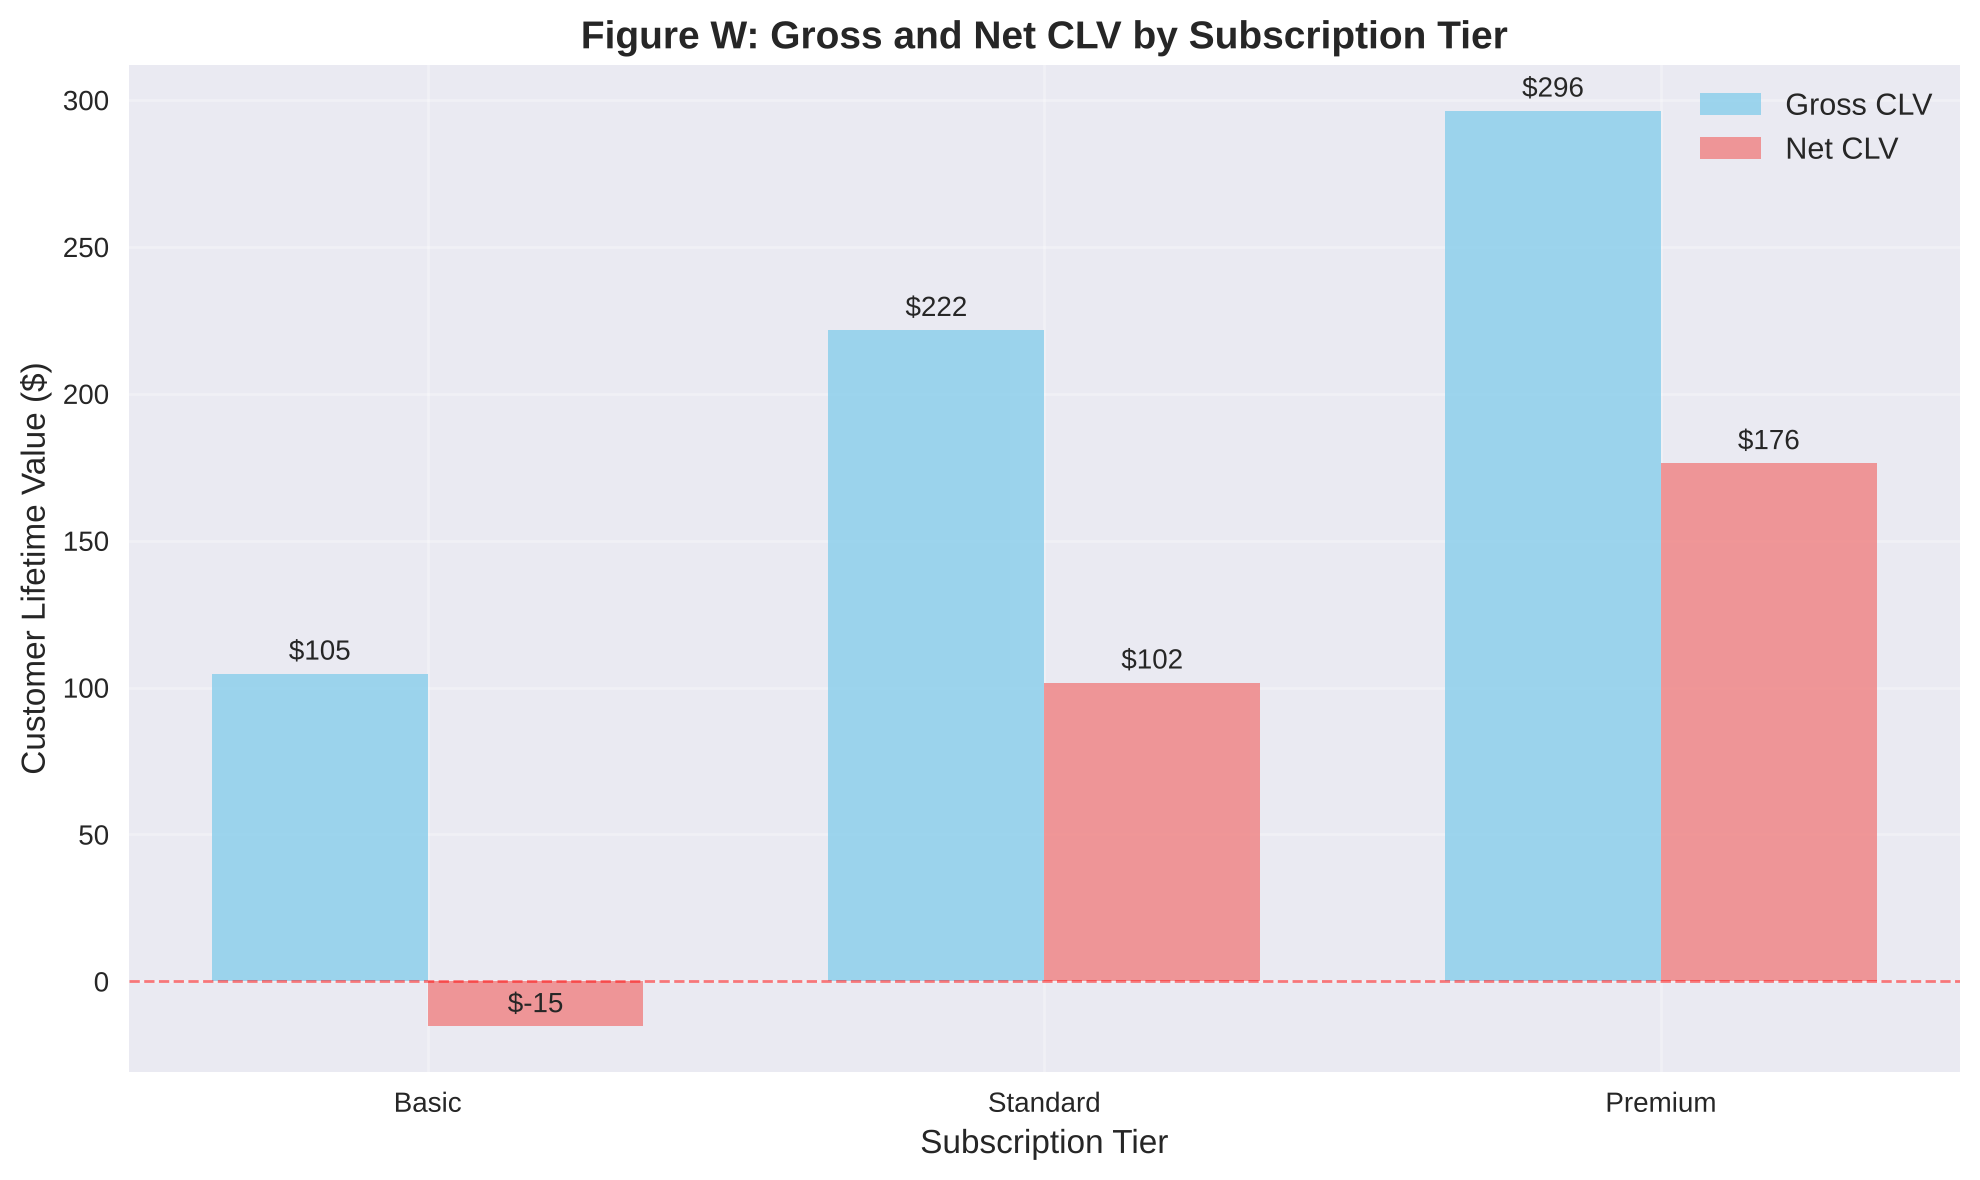

In [23]:
# Figure W: Gross and Net CLV by Subscription Tier
# Set style for better-looking plots
plt.style.use('seaborn-v0_8')

# Values come from the CLV analysis in the cell above
tiers = ['Basic', 'Standard', 'Premium']
subscription_data = {
    'Subscription_Tier': tiers,
    'Gross_CLV': [clv_analysis[t]['gross_clv'] for t in tiers],
    'Net_CLV': [clv_analysis[t]['net_clv'] for t in tiers]
}

df_viz = pd.DataFrame(subscription_data)

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(df_viz['Subscription_Tier']))
width = 0.35

# Create bars
bars1 = ax.bar(x - width/2, df_viz['Gross_CLV'], width, label='Gross CLV', alpha=0.8, color='skyblue')
bars2 = ax.bar(x + width/2, df_viz['Net_CLV'], width, label='Net CLV', alpha=0.8, color='lightcoral')

# Customize the plot
ax.set_xlabel('Subscription Tier', fontsize=12)
ax.set_ylabel('Customer Lifetime Value ($)', fontsize=12)
ax.set_title('Figure W: Gross and Net CLV by Subscription Tier', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_viz['Subscription_Tier'])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax.annotate(f'${height:.0f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10)
for bar in bars2:
    height = bar.get_height()
    ax.annotate(f'${height:.0f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10)

# Add a horizontal line at y=0 for reference
ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, linewidth=1)

plt.tight_layout()
plt.show()

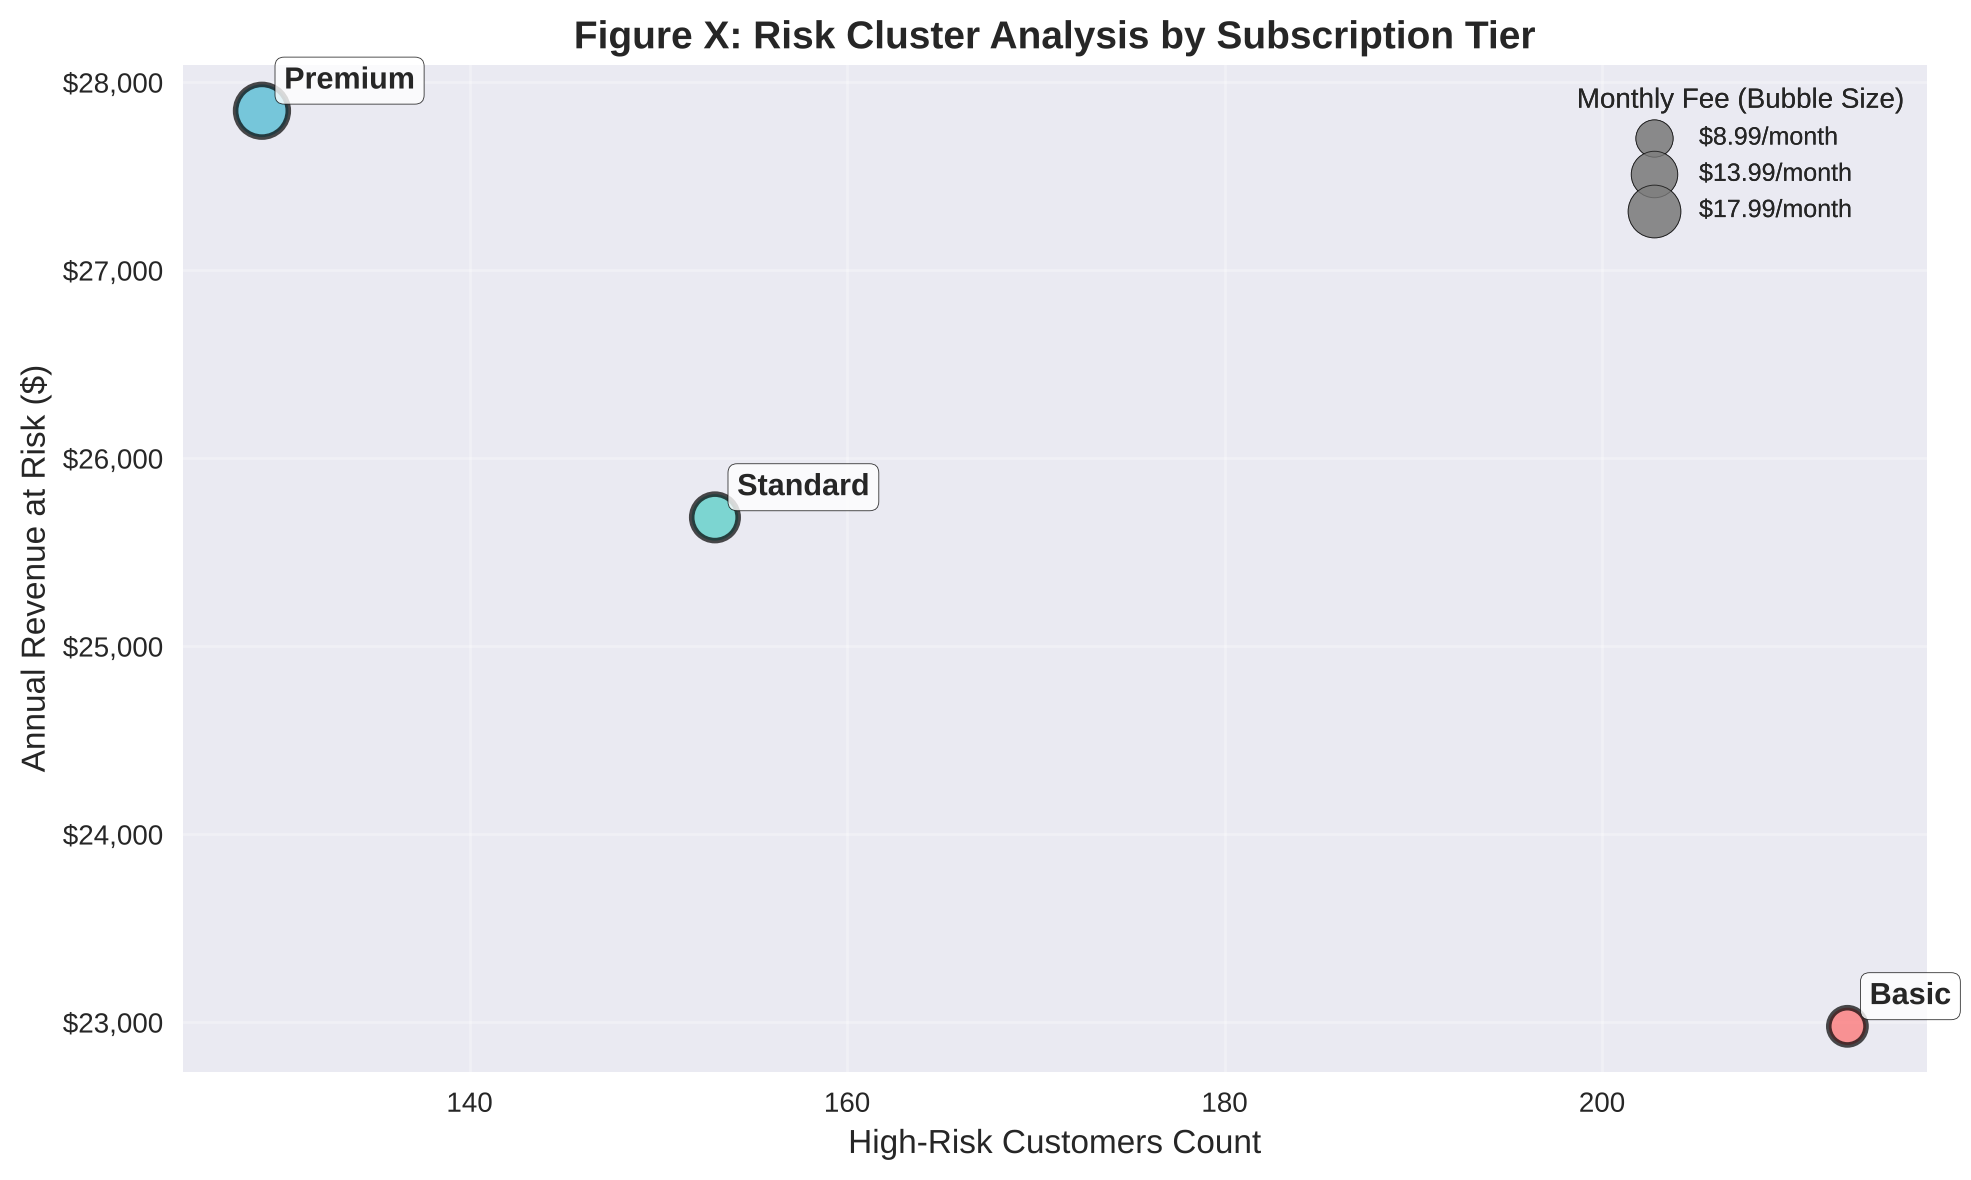

In [24]:
# Figure X: Risk Cluster Analysis by Subscription Tier
# Set style
plt.style.use('seaborn-v0_8')

# Data for risk analysis
tiers = ['Basic', 'Standard', 'Premium']
risk_data = {
    'Subscription_Tier': tiers,
    'High_Risk_Customers': [clv_analysis[t]['high_risk_customers'] for t in tiers],
    'Annual_Revenue_at_Risk': [clv_analysis[t]['revenue_at_risk'] for t in tiers],
    'Average_Monthly_Fee': [clv_analysis[t]['avg_monthly_fee'] for t in tiers]
}

df_risk = pd.DataFrame(risk_data)

# Create the scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

# Create scatter plot with bubble sizes based on monthly fee
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']  # Red, Teal, Blue
scatter = ax.scatter(df_risk['High_Risk_Customers'], 
                    df_risk['Annual_Revenue_at_Risk'], 
                    s=df_risk['Average_Monthly_Fee']*20,  # Size based on monthly fee
                    c=colors, 
                    alpha=0.7, 
                    edgecolors='black', 
                    linewidth=2)

# Customize the plot
ax.set_xlabel('High-Risk Customers Count', fontsize=12)
ax.set_ylabel('Annual Revenue at Risk ($)', fontsize=12)
ax.set_title('Figure X: Risk Cluster Analysis by Subscription Tier', fontsize=14, fontweight='bold')

# Add tier labels to each point
for i, tier in enumerate(df_risk['Subscription_Tier']):
    ax.annotate(tier, 
                (df_risk['High_Risk_Customers'][i], df_risk['Annual_Revenue_at_Risk'][i]),
                xytext=(8, 8), 
                textcoords='offset points', 
                fontsize=11, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# Add grid and formatting
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add legend for bubble sizes
legend_elements = [plt.scatter([], [], s=fee*20, c='gray', alpha=0.7, edgecolors='black') 
                   for fee in [9, 14, 18]]
legend_labels = ['$8.99/month', '$13.99/month', '$17.99/month']
legend1 = ax.legend(legend_elements, legend_labels, 
                   title='Monthly Fee (Bubble Size)', 
                   loc='upper right', fontsize=9)
ax.add_artist(legend1)

plt.tight_layout()
plt.show()

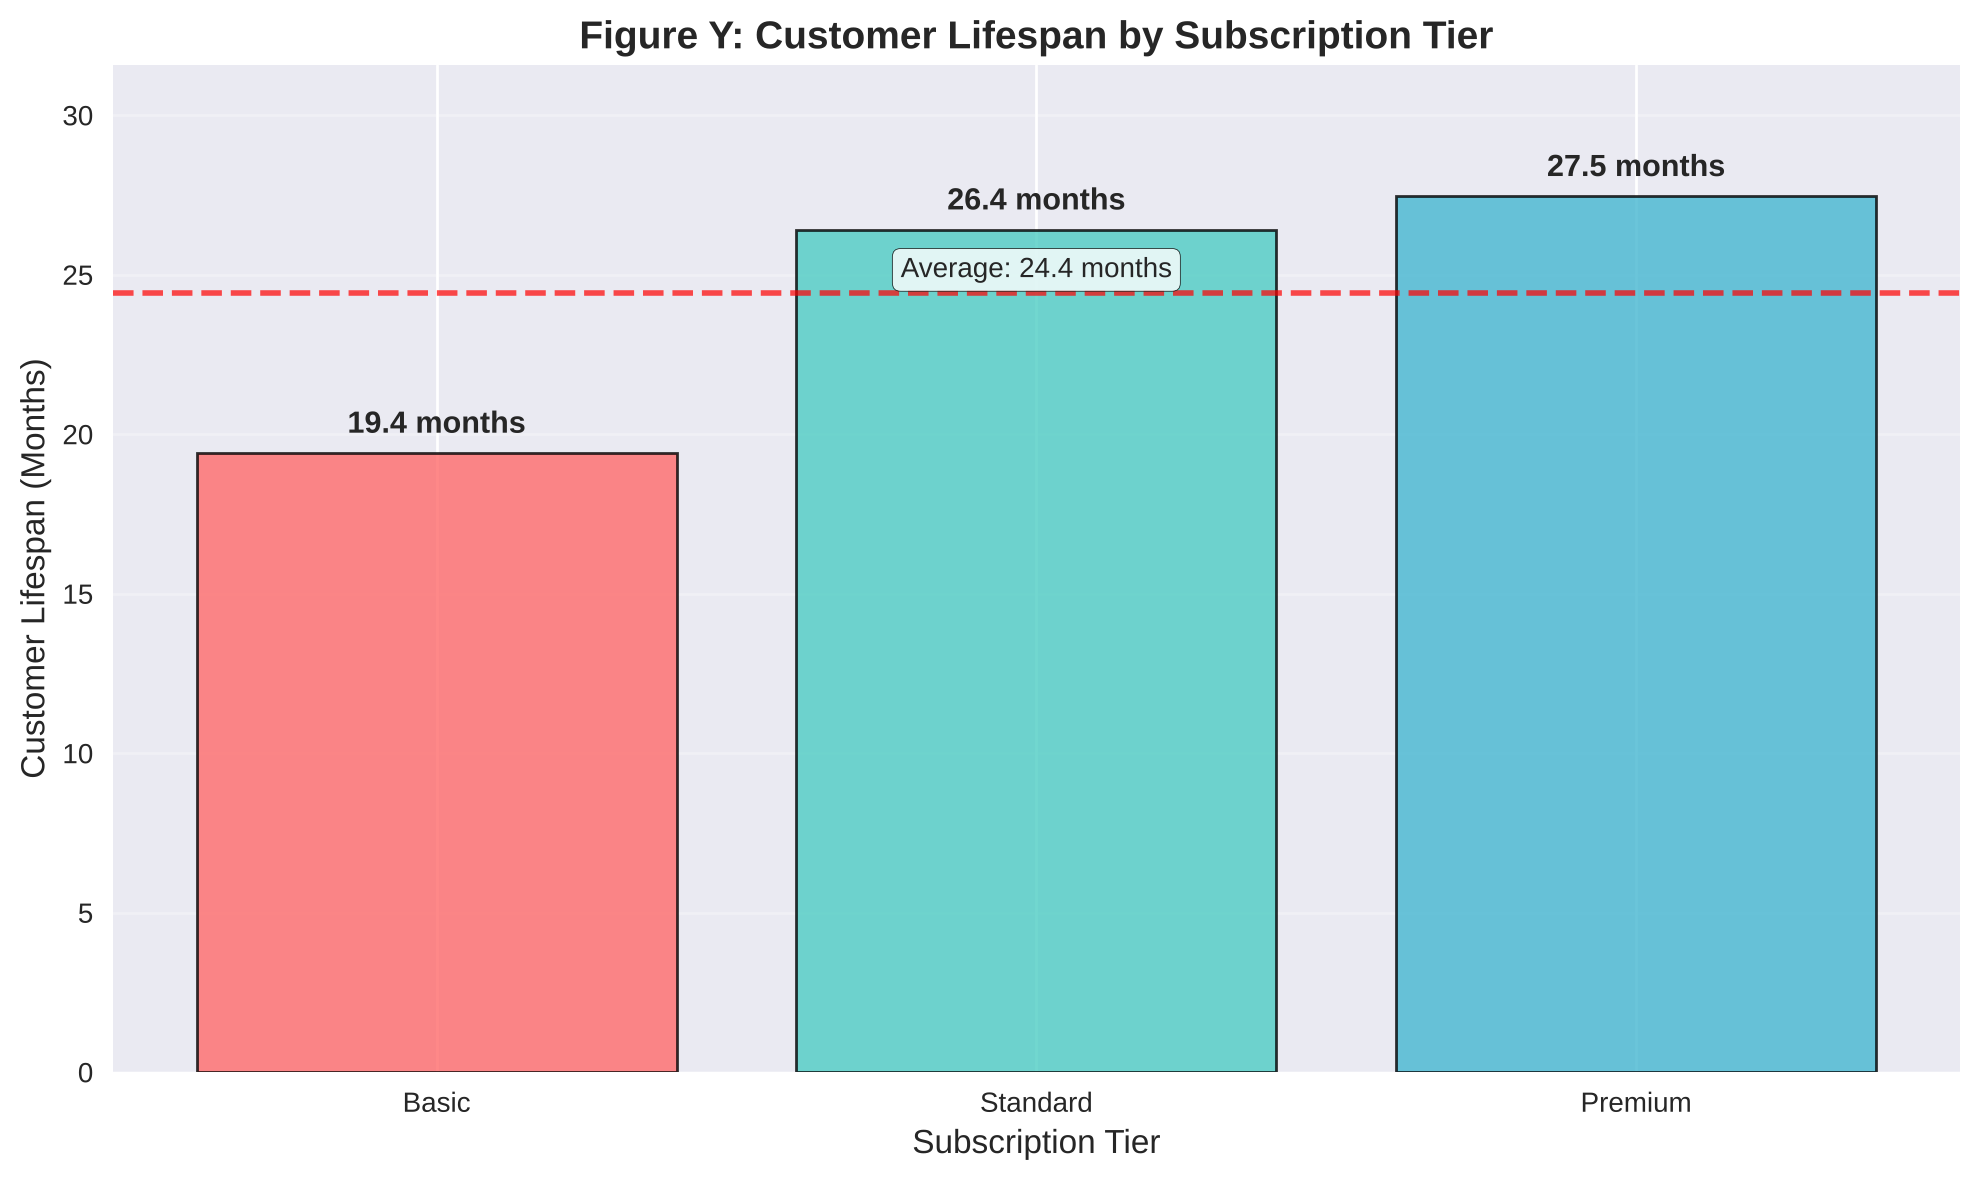

In [25]:
# Figure Y: Customer Lifespan by Subscription Tier
# Set style
plt.style.use('seaborn-v0_8')

# Data for lifespan analysis
tiers = ['Basic', 'Standard', 'Premium']
lifespan_data = {
    'Subscription_Tier': tiers,
    'Customer_Lifespan_Months': [clv_analysis[t]['customer_lifespan_months'] for t in tiers]
}

df_lifespan = pd.DataFrame(lifespan_data)

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

# Create bars with gradient colors
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']  # Red to Blue gradient
bars = ax.bar(df_lifespan['Subscription_Tier'], 
              df_lifespan['Customer_Lifespan_Months'], 
              color=colors, 
              alpha=0.8,
              edgecolor='black',
              linewidth=1)

# Customize the plot
ax.set_ylabel('Customer Lifespan (Months)', fontsize=12)
ax.set_xlabel('Subscription Tier', fontsize=12)
ax.set_title('Figure Y: Customer Lifespan by Subscription Tier', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f} months', 
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 5), 
                textcoords="offset points", 
                ha='center', 
                va='bottom',
                fontsize=11,
                fontweight='bold')

# Add average line
avg_lifespan = df_lifespan['Customer_Lifespan_Months'].mean()
ax.axhline(y=avg_lifespan, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax.text(1, avg_lifespan + 0.5, f'Average: {avg_lifespan:.1f} months', 
        ha='center', fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# Set y-axis to start from 0 for better comparison
ax.set_ylim(0, max(df_lifespan['Customer_Lifespan_Months']) * 1.15)

plt.tight_layout()
plt.show()

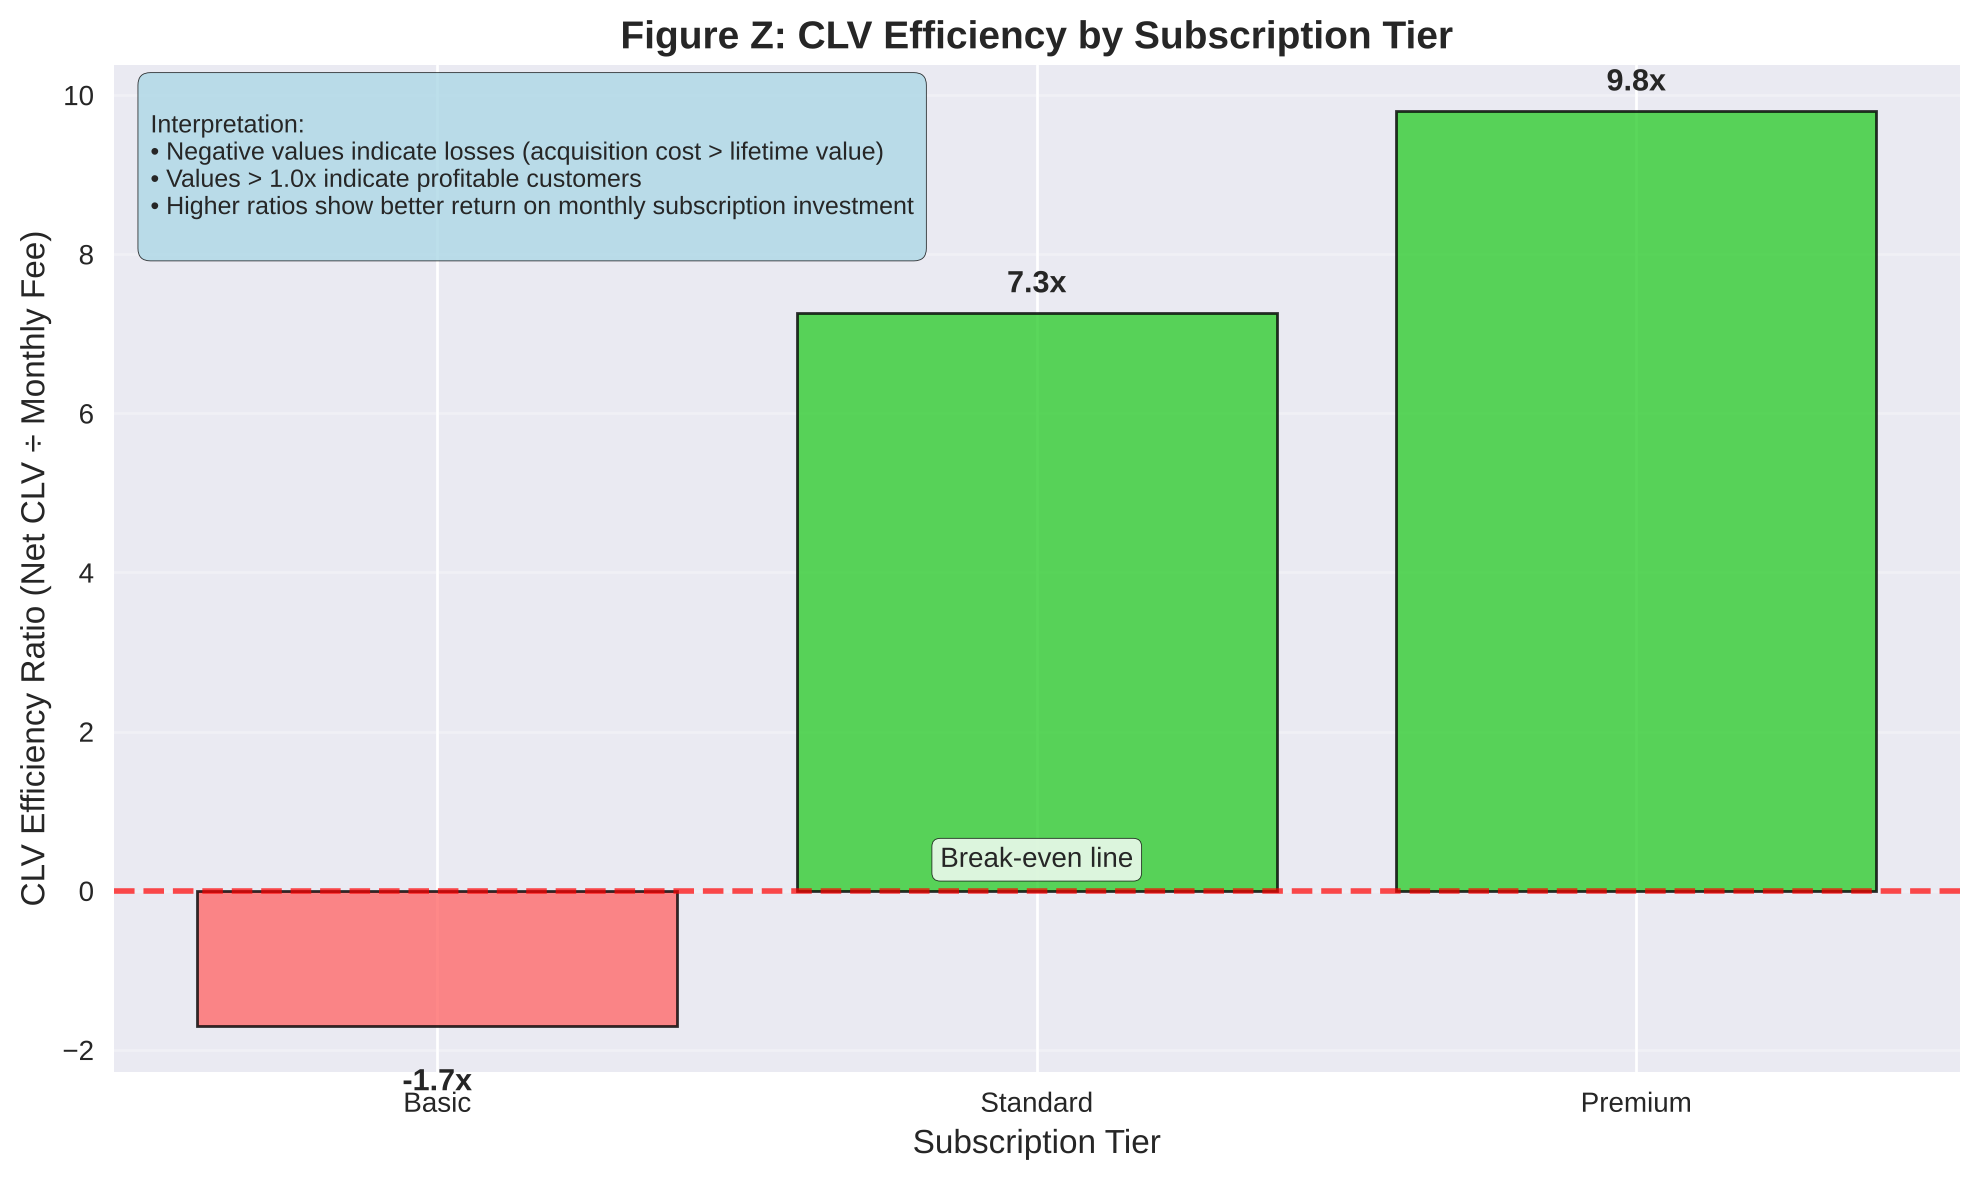

In [26]:
# Figure Z: CLV Efficiency by Subscription Tier (Net CLV / Monthly Fee)
# Set style
plt.style.use('seaborn-v0_8')

# Data for efficiency analysis
tiers = ['Basic', 'Standard', 'Premium']
efficiency_data = {
    'Subscription_Tier': tiers,
    'Net_CLV': [clv_analysis[t]['net_clv'] for t in tiers],
    'Average_Monthly_Fee': [clv_analysis[t]['avg_monthly_fee'] for t in tiers]
}

df_efficiency = pd.DataFrame(efficiency_data)

# Calculate CLV efficiency ratio
df_efficiency['CLV_Efficiency'] = df_efficiency['Net_CLV'] / df_efficiency['Average_Monthly_Fee']

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

# Color bars based on efficiency (negative = red, positive = green gradient)
colors = []
for efficiency in df_efficiency['CLV_Efficiency']:
    if efficiency < 0:
        colors.append('#FF6B6B')  # Red for negative
    elif efficiency < 5:
        colors.append('#FFA500')  # Orange for low positive
    else:
        colors.append('#32CD32')  # Green for good positive

bars = ax.bar(df_efficiency['Subscription_Tier'], 
              df_efficiency['CLV_Efficiency'], 
              color=colors, 
              alpha=0.8,
              edgecolor='black',
              linewidth=1)

# Customize the plot
ax.set_ylabel('CLV Efficiency Ratio (Net CLV ÷ Monthly Fee)', fontsize=12)
ax.set_xlabel('Subscription Tier', fontsize=12)
ax.set_title('Figure Z: CLV Efficiency by Subscription Tier', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Add horizontal line at y=0 for reference (break-even point)
ax.axhline(y=0, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax.text(1, 0.3, 'Break-even line', ha='center', fontsize=10, 
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}x', 
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 5 if height >= 0 else -15), 
                textcoords="offset points", 
                ha='center', 
                va='bottom' if height >= 0 else 'top',
                fontsize=11,
                fontweight='bold')

# Add interpretation text
interpretation_text = """
Interpretation:
• Negative values indicate losses (acquisition cost > lifetime value)
• Values > 1.0x indicate profitable customers
• Higher ratios show better return on monthly subscription investment
"""

ax.text(0.02, 0.98, interpretation_text, transform=ax.transAxes, 
        fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='lightblue', alpha=0.8))

plt.tight_layout()
plt.show()

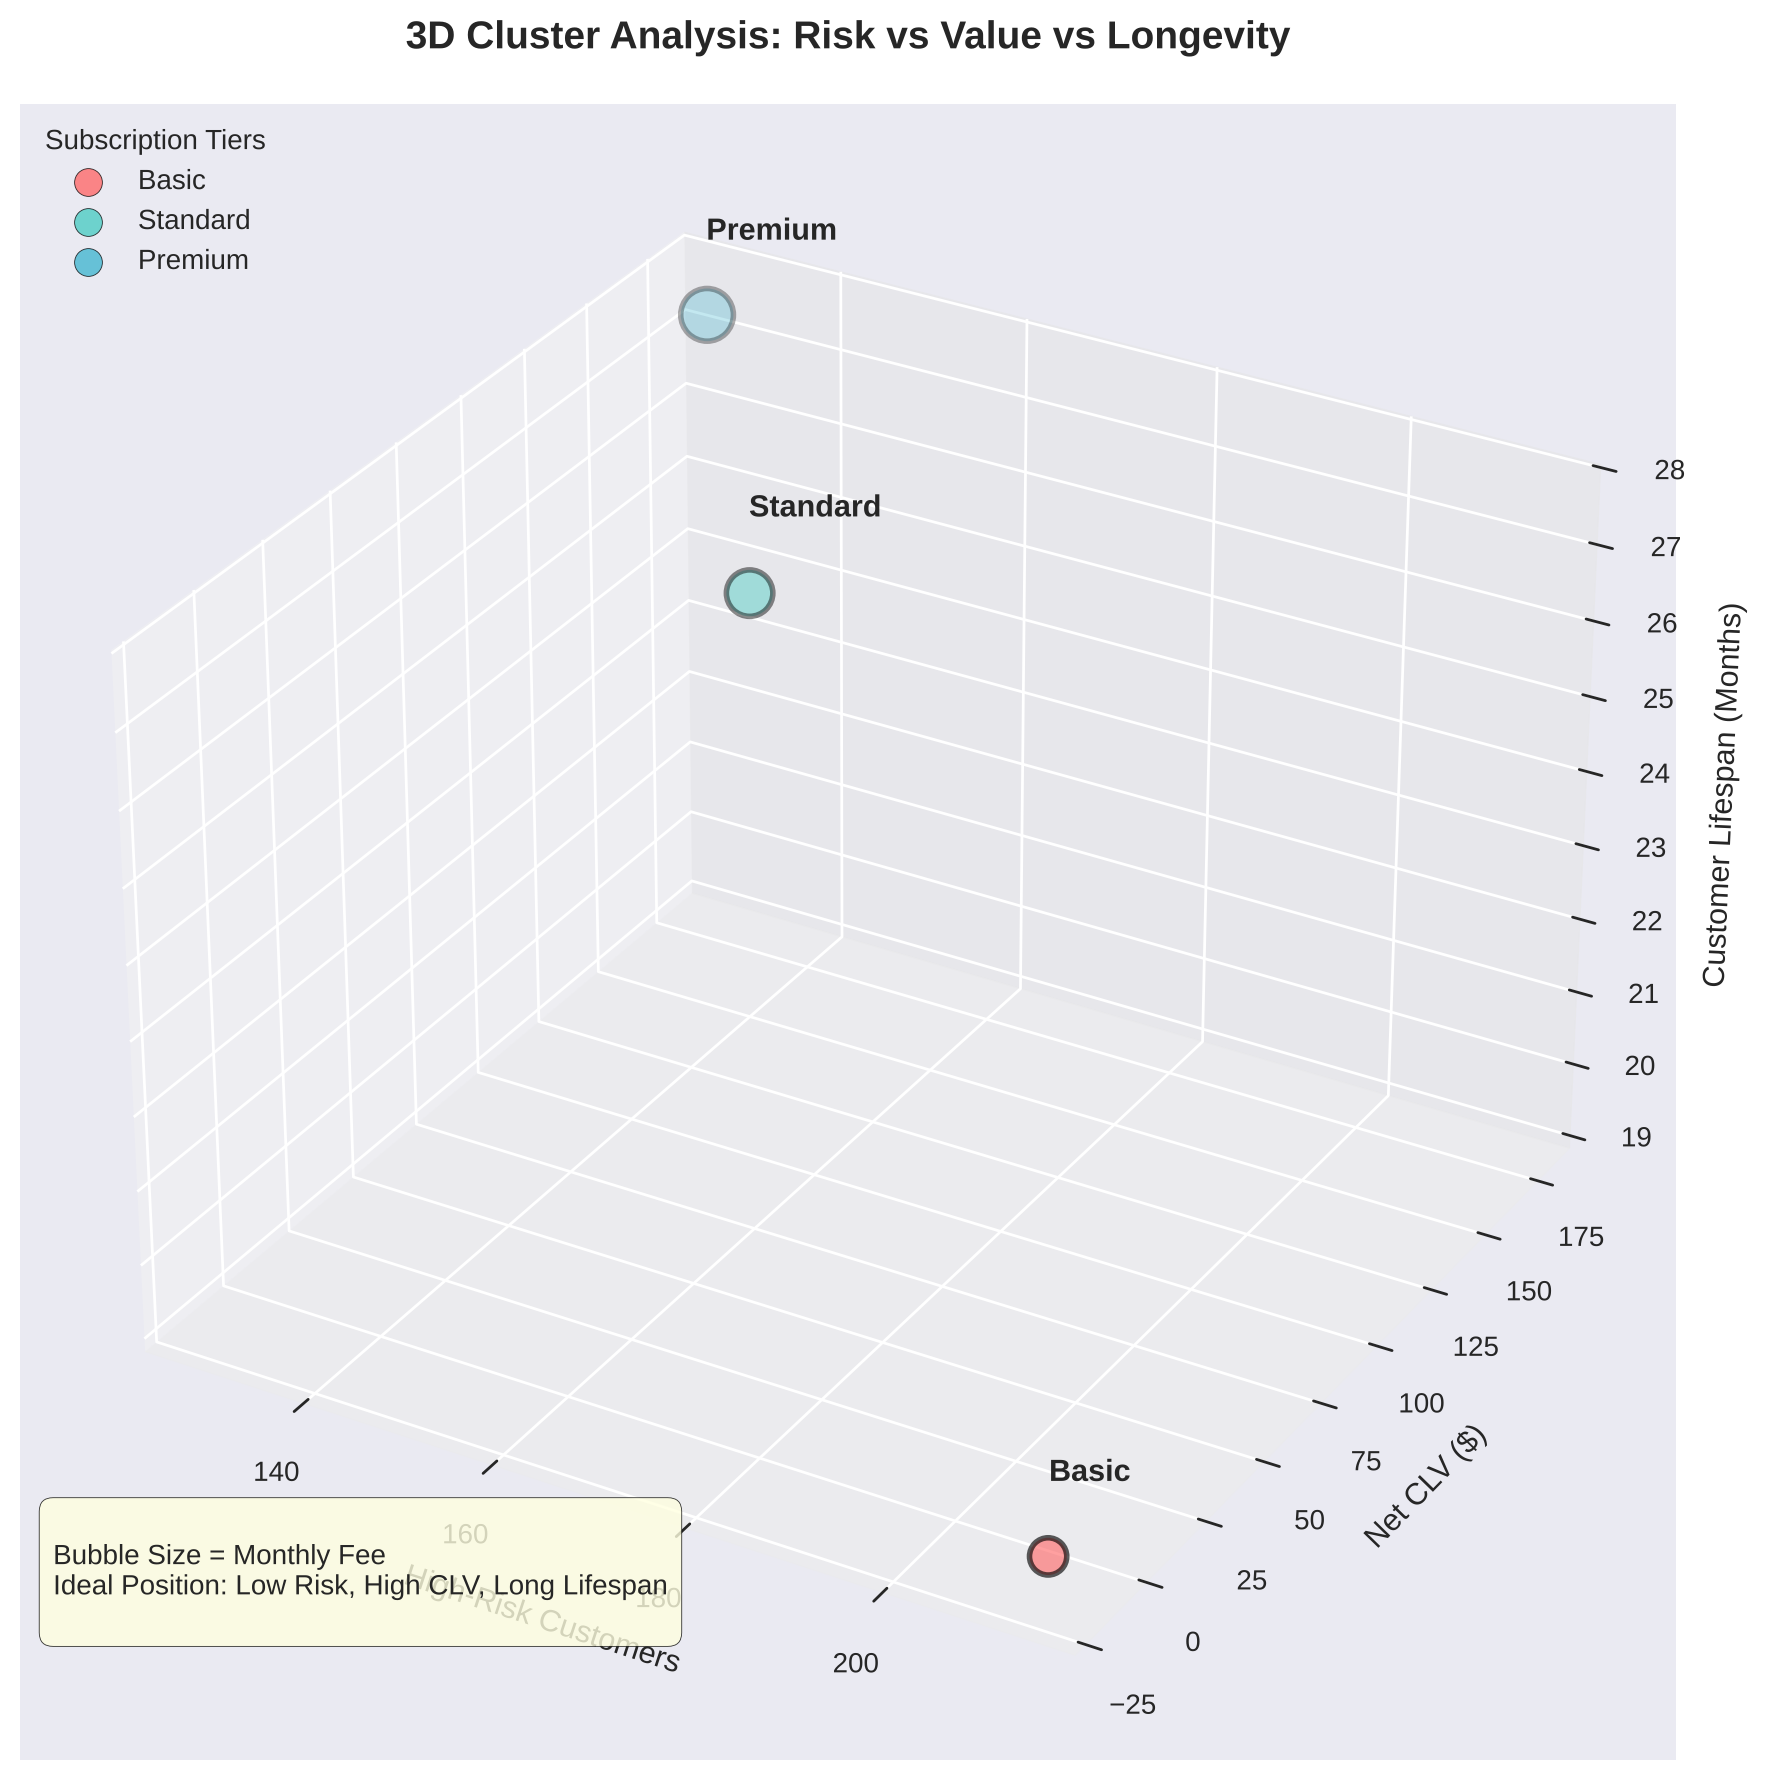

In [27]:
# 3D Cluster Analysis: Risk vs Value vs Longevity
# Data for 3D analysis
tiers = ['Basic', 'Standard', 'Premium']
cluster_data = {
    'Subscription_Tier': tiers,
    'High_Risk_Customers': [clv_analysis[t]['high_risk_customers'] for t in tiers],
    'Net_CLV': [clv_analysis[t]['net_clv'] for t in tiers],
    'Customer_Lifespan_Months': [clv_analysis[t]['customer_lifespan_months'] for t in tiers],
    'Average_Monthly_Fee': [clv_analysis[t]['avg_monthly_fee'] for t in tiers]
}

df_3d = pd.DataFrame(cluster_data)

# Create 3D plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Colors and sizes for each tier
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']  # Red, Teal, Blue
sizes = df_3d['Average_Monthly_Fee'] * 20

# Create 3D scatter plot
scatter = ax.scatter(df_3d['High_Risk_Customers'], 
                    df_3d['Net_CLV'], 
                    df_3d['Customer_Lifespan_Months'],
                    c=colors, 
                    s=sizes, 
                    alpha=0.8, 
                    edgecolors='black',
                    linewidth=2)

# Customize the plot
ax.set_xlabel('High-Risk Customers', fontsize=11, labelpad=10)
ax.set_ylabel('Net CLV ($)', fontsize=11, labelpad=10)
ax.set_zlabel('Customer Lifespan (Months)', fontsize=11, labelpad=10)
ax.set_title('3D Cluster Analysis: Risk vs Value vs Longevity', fontsize=14, fontweight='bold', pad=20)

# Add tier labels to each point
for i, tier in enumerate(df_3d['Subscription_Tier']):
    ax.text(df_3d['High_Risk_Customers'][i], 
            df_3d['Net_CLV'][i], 
            df_3d['Customer_Lifespan_Months'][i] + 1,
            tier, 
            fontsize=11, 
            fontweight='bold')

# Add grid
ax.grid(True, alpha=0.3)

# Create custom legend
legend_elements = []
for i, tier in enumerate(df_3d['Subscription_Tier']):
    legend_elements.append(plt.scatter([], [], c=colors[i], s=100, alpha=0.8, edgecolors='black'))

ax.legend(legend_elements, df_3d['Subscription_Tier'], 
          title='Subscription Tiers', loc='upper left', bbox_to_anchor=(0, 1))

# Add interpretation box
interpretation = """
Bubble Size = Monthly Fee
Ideal Position: Low Risk, High CLV, Long Lifespan
"""
ax.text2D(0.02, 0.15, interpretation, transform=ax.transAxes, 
          fontsize=10, verticalalignment='top',
          bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.show()

In [28]:
# Risk Distribution Investigation
print("\n" + "="*60)
print("RISK DISTRIBUTION PATTERN ANALYSIS")
print("="*60)

# Analyze the polarized distribution
prob_distribution = pd.cut(y_prob_best, bins=10, labels=[f'{i/10:.1f}-{(i+1)/10:.1f}' for i in range(10)])
dist_counts = prob_distribution.value_counts().sort_index()

print("Probability Distribution Analysis:")
print("-" * 35)
for bin_name, count in dist_counts.items():
    percentage = count / len(y_prob_best) * 100
    print(f"  {bin_name}: {count} customers ({percentage:.1f}%)")

# Check if this pattern makes business sense
print(f"\nBusiness Logic Validation:")
print("-" * 30)

# Analyze key features for each risk group
high_risk_mask = y_prob_best >= 0.7
low_risk_mask = y_prob_best < 0.3
medium_risk_mask = (y_prob_best >= 0.3) & (y_prob_best < 0.7)

for feature in ['avg_watch_time_per_day', 'watch_hours', 'last_login_days']:
    if feature in X_test.columns:
        feature_idx = list(X_test.columns).index(feature)
        high_risk_avg = X_test.iloc[high_risk_mask, feature_idx].mean()
        low_risk_avg = X_test.iloc[low_risk_mask, feature_idx].mean()
        medium_risk_avg = X_test.iloc[medium_risk_mask, feature_idx].mean() if medium_risk_mask.sum() > 0 else 0
        
        print(f"  {feature}:")
        print(f"    High Risk: {high_risk_avg:.2f}")
        print(f"    Medium Risk: {medium_risk_avg:.2f}")
        print(f"    Low Risk: {low_risk_avg:.2f}")

print(f"\nPattern Explanation:")
print(f"The polarized distribution suggests customers have distinct behavioral")
print(f"patterns - they either engage heavily (low churn risk) or minimally")
print(f"(high churn risk), with few customers in between. This is common in")
print(f"subscription services where engagement strongly predicts retention.")


RISK DISTRIBUTION PATTERN ANALYSIS
Probability Distribution Analysis:
-----------------------------------
  0.0-0.1: 460 customers (46.0%)
  0.1-0.2: 21 customers (2.1%)
  0.2-0.3: 15 customers (1.5%)
  0.3-0.4: 2 customers (0.2%)
  0.4-0.5: 3 customers (0.3%)
  0.5-0.6: 2 customers (0.2%)
  0.6-0.7: 2 customers (0.2%)
  0.7-0.8: 3 customers (0.3%)
  0.8-0.9: 10 customers (1.0%)
  0.9-1.0: 482 customers (48.2%)

Business Logic Validation:
------------------------------
  avg_watch_time_per_day:
    High Risk: 0.15
    Medium Risk: 0.39
    Low Risk: 1.55
  watch_hours:
    High Risk: 5.36
    Medium Risk: 8.37
    Low Risk: 18.46
  last_login_days:
    High Risk: 37.87
    Medium Risk: 17.89
    Low Risk: 22.45

Pattern Explanation:
The polarized distribution suggests customers have distinct behavioral
patterns - they either engage heavily (low churn risk) or minimally
(high churn risk), with few customers in between. This is common in
subscription services where engagement strongly p

In [29]:
# Save results
import os
os.makedirs('../outputs', exist_ok=True)
results_df.to_csv('../outputs/model_comparison_results.csv', index=False)
print(f"\nResults saved to ../outputs/model_comparison_results.csv")
print("Analysis complete.")


Results saved to ../outputs/model_comparison_results.csv
Analysis complete.
